<div align="center">
    
# ΠΑΝΕΠΙΣΤΗΜΙΟ ΚΡΗΤΗΣ
# Τμήμα Επιστήμης Υπολογιστών

## HY-215: Εφαρμοσμένα Μαθηματικά για Μηχανικούς
## Εαρινό Εξάμηνο 2025-2026
### Διδάσκοντες: Γ. Στυλιανού, Γ. Καφεντζής
    
## Ανάθεση: 13-4-2026
## Παράδοση (ηλεκτρονικά, όπως αναφέρεται στο τέλος του αρχείου αυτού): 
## Δευτέρα, 4-5-2026, 23:59:59
<h1><center>4η Σειρά Εργαστηρίου</center></h1>

Σε κάθε άσκηση `Python`, εισάγουμε πρώτα τις βιβλιοθήκες που θα χρησιμοποιήσουμε: εδώ, θα χρειαστούμε τις `numpy`, `matplotlib`, `Ipython`, και `scipy`, καθώς και μια custom βιβλιοθήκη.

Επιλέξτε το παρακάτω κελί κώδικα και πατήστε Shift + Enter, ώστε να το εκτελέσετε. 

Το ίδιο θα κάνετε με οποιοδήποτε κελί κώδικα. Αν τροποποιήσετε κάποιο κελί κώδικα, θα πρέπει να το ξανατρέξετε για να δείτε τα αποτελέσματά του.

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.io.wavfile as wav
from utils import ctft, rect, tri, ctft2ictft, plotter
from IPython.display import Audio
from scipy.io import loadmat
np.random.seed(1367)
%matplotlib inline

---
---

### Άσκηση 1 (πολύ σημαντική για τη συνέχεια του εργαστηρίου αυτού): Επίδειξη μιας απλής προσέγγισης του Μετασχ. Fourier

Συζητήσαμε αρκετά στις διαλέξεις για τον μετασχηματισμό Fourier και βρήκαµε τη μαθηματική του έκφραση για αρκετά γνωστά µας σήματα. Ο μετασχ. Fourier είναι μια συνεχής συνάρτηση του $f$, ως εκ τούτου δεν μπορεί να υλοποιηθεί απ' ευθείας σε υπολογιστή - πρέπει πρώτα να τον "διακριτοποιήσουμε"/προσεγγίσουμε με κάποιο τρόπο, και αναγκαστικά να εισάγουμε σφάλμα. Το σφάλμα αυτό προέρχεται από τρεις πηγές.

1. Από το γεγονός ότι ο άξονας του χρόνου δε θα είναι ($-\infty, +\infty$) όπως στη θεωρία αλλά κάποιο πεπερασμένο διάστημα $(-Τ, Τ)$.
2. Από το γεγονός ότι ο άξονας της συχνότητας δε θα είναι ($-\infty, +\infty$) όπως στη θεωρία αλλά κάποιο πεπερασμένο διάστημα $(-Β, Β)$.
3. Από το γεγονός ότι τα παραπάνω πεπερασμένα διαστήματα δεν περιέχουν άπειρες χρονικές/συχνοτικές στιγμές αλλά πεπερασμένες (π.χ. στο διάστημα $(-2,2)$ μπορούμε να πάρουμε πολλά δείγματα, αλλά όχι άπειρα).

---

$\underline{Σημείωση}:$ Στην `Python`, φυσικά, υπάρχουν πολλές βιβλιοθήκες που διαθέτουν συνάρτηση για τον υπολογισμό **κάποιου** μετασχηματισμού Fourier ενός σήματος, με τις πιο δημοφιλείς να είναι οι $\texttt{fft/ifft}$ της βιβλιοθήκης $\texttt{NumPy}$ και οι (ακόμα πιο γρήγορες) $\texttt{fft/ifft}$ της βιβλιοθήκης $\texttt{SciPy}$.  Παρ΄ όλα αυτά, εμείς θα φτιάξουμε τις δικές µας, για να έχουμε απόλυτο έλεγχο και στο τέλος του εργαστηρίου θα σας δείξουμε πως να χρησιμοποιείτε αυτές τις έτοιμες συναρτήσεις για να υλοποιήσετε το μετασχ. Fourier που συζητάμε.

---

$\left(\alpha'\right)$ Ας πάμε να υπολογίσουμε το μετασχ. Fourier (και να απεικονίσουμε το φάσμα πλάτους) του πολύ γνωστού μας σήματος 

$$\large x(t) = e^{-at}u(t), \: \: a > 0$$

για κάποια τιμή του $a$. Γνωρίζετε ήδη ότι

$$\large X(f) = \frac{1}{a + j2\pi f}$$

Ας ξεκινήσουμε στο πεδίο του χρόνου, κατασκευάζοντας το σήμα $x(t)$ για $a=2$ και για διάρκεια μόλις $10$ δευτερολέπτων (αντί για άπειρη διάρκεια που έχει κανονικά το σήμα).

(i.) ΠΡΟΣΕΞΕΤΕ: Ο άξονας t θα έχει τις τιμές: [0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1 ] ... [ 9.91  9.92  9.93  9.94  9.95  9.96  9.97  9.98  9.99 10.  ] sec

(ii.) Πόσες χρονικές στιγμές πήραμε? 1000!


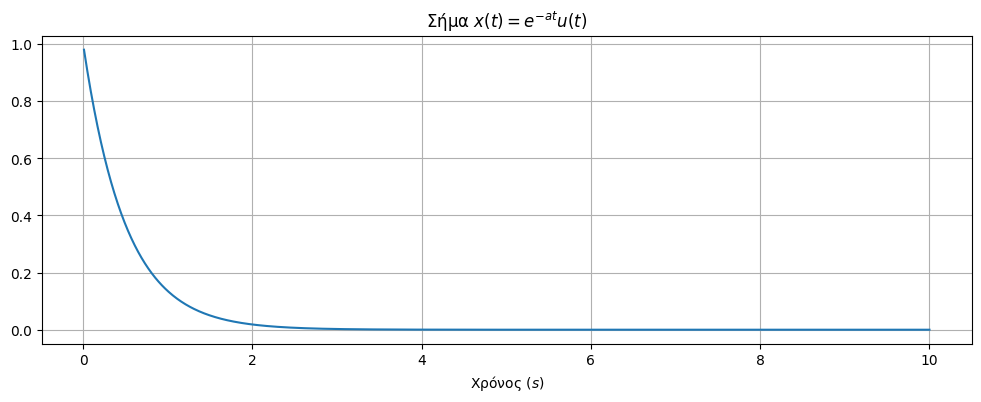

In [53]:
Dt = 0.01                                    # Βήμα στο χρόνο.
D = 10                                       # Διάρκεια του σήματος (θεωρητικά είναι άπειρης διάρκειας αλλά... you know :) )
t = np.arange(start=Dt, stop=D+Dt, step=Dt)  # Άξονας του χρόνου, από 0+ ως D=10 με βήμα Dt <--- ΠΑΡΑΤΗΡΗΣΤΕ ΠΩΣ ΔΕΙΓΜΑΤΟΛΗΠΤΗΣΑΜΕ ΤΟ ΣΥΝΕΧΗ ΑΞΟΝΑ t!

print(f"(i.) ΠΡΟΣΕΞΕΤΕ: Ο άξονας t θα έχει τις τιμές: {t[0:10]} ... {t[-10:]} sec\n")
print(f"(ii.) Πόσες χρονικές στιγμές πήραμε? {len(t)}!")

a = 2                                    # Παράμετρος α, έστω ίση με 2 στο παράδειγμά μας.
x = np.exp(-a*t)                         # Σήμα (δε χρειάζεται η βηματική u(t) γιατί ο άξονας t, όπως τον φτιάξαμε, ξεκινά από το μηδέν)

plt.figure(figsize=(12,4))               # Σχήμα (μέγεθος)
plt.plot(t, x)                           # Γράφημα.
plt.xlabel("Χρόνος $(s)$")               # Ομορφαίνουμε.
plt.title("Σήμα $x(t) = e^{-at}u(t)$")   # Ομορφαίνουμε.
plt.grid()                               # Ομορφαίνουμε.
plt.show()

Εδώ παραλείψαµε να χρησιμοποιήσουμε ρητά τη βηµατική συνάρτηση $u(t)$, αφού ο άξονας του χρόνου $t$ που δηµιουργήσαµε πριν ορίζεται για $t>0$, οπότε ουσιαστικά την έχουμε "ενσωματώσει" κατά τη δημιουργία του άξονα $t$.

Έστω ότι θέλουμε να βρούμε το συχνοτικό περιεχόμενο του σήματος στο διάστηµα $f \in [−10, 10]$ Hz, µε ίδια "ανάλυση" (βήμα) όπως και στο πεδίο του χρόνου, δηλ. $0.01$ Hz. Κατασκευάζουµε τον άξονα των συχνοτήτων ως :

In [54]:
Df = 0.01                                      # Βήμα στη συχνότητα.
f = np.arange(start=-10, stop=10+Df, step=Df)  # Άξονας της συχνότητας, [-10, 10] Hz με βήμα Df  <--- ΠΑΡΑΤΗΡΗΣΤΕ ΠΩΣ ΔΕΙΓΜΑΤΟΛΗΠΤΗΣΑΜΕ ΤΟ ΣΥΝΕΧΗ ΑΞΟΝΑ f!

print(f"(i.) ΠΡΟΣΕΞΤΕ: Ο άξονας f θα έχει τις τιμές: {f[0:5]} ... {f[-5:]} Hz\n")
print(f"(ii.) Πόσες συχνοτικές στιγμές πήραμε? {len(f)}!")

(i.) ΠΡΟΣΕΞΤΕ: Ο άξονας f θα έχει τις τιμές: [-10.    -9.99  -9.98  -9.97  -9.96] ... [ 9.96  9.97  9.98  9.99 10.  ] Hz

(ii.) Πόσες συχνοτικές στιγμές πήραμε? 2001!


Θεωρούμε λοιπόν ότι µας ενδιαφέρουν μόνο οι παραπάνω συχνότητες $[−10, 10]$ Hz, µε ανάλυση $Df$, και ότι σε αυτές τις συχνότητες, $2001$ το πλήθος, θα υπολογίσουμε τον μετασχηματισμό Fourier. ΄Αρα, ουσιαστικά, θα "βλέπουμε" τον μετασχηματισμό Fourier μόνο στο διάστηµα $[−10, 10]$ Hz. 

Γνωρίζοντας τα δείγματα του χρόνου και της συχνότητας μπορούμε να κατασκευάσουµε το λεγόμενο $\textit{πίνακα ανάλυσης}$ του μετασχηματισμού Fourier:

$$\large M(f_l, t_n) = e^{−j2πf_l t_n} = \begin{bmatrix} e^{-j2\pi t_{1} f_{1}} & e^{-j2\pi t_2 f_1} & \cdots & e^{-j2\pi t_{1000} f_1} \\
e^{-j2\pi t_{1} f_{2}} & e^{-j2\pi t_2 f_2} & \cdots & e^{-j2\pi t_{1000} f_{2}} \\
\cdots & \cdots & \cdots & \cdots\\
\cdots & \cdots & \cdots & \cdots\\
e^{-j2\pi t_{1} f_{1999}} & e^{-j2\pi t_{2} f_{1999}} & \cdots & e^{-j2\pi t_{1000} f_{1999}} \\
e^{-j2\pi t_{1} f_{2000}} & e^{-j2\pi t_{2} f_{2000}} & \cdots & e^{-j2\pi t_{1000} f_{2000}} \\
e^{-j2\pi t_{1} f_{2001}} & e^{-j2\pi t_{2} f_{2001}} & \cdots & e^{-j2\pi t_{1000} f_{2001}} 
 \end{bmatrix}$$

με τους δείκτες $n, l$ να υποδεικνύουν ότι οι μεταβλητές αυτές είναι διακριτές: έχουμε λάβει μόνο κάποια δείγματα από τις συνεχείς μεταβλητές $f, t$, όπως ακριβώς κάναμε μόλις πριν, χρησιμοποιώντας τα βήματα $Dt$, $Df$, για να δειγματοληπτήσουμε τους αντίστοιχους άξονες. Μάλιστα πήραμε $2001$ δείματα στο χώρο της συχνότητας και $1000$ δείγματα στο χώρο του χρόνου! 

Βλέπετε ότι η πρώτη γραμμή του πίνακα περιλαμβάνει τα μιγαδικά εκθετικά με συχνότητα $f_1$, για κάθε χρονική στιγμή $t$ ($t_1, t_2, \cdots, t_{1000}$) που πήραμε κατά τη δειγματοληψία της συνεχούς μεταβλητής $t$. Η δεύτερη γραμμή περιλαμβάνει τα μιγαδικά εκθετικά με συχνότητα $f_2$, ξανά για κάθε χρονική στιγμή $t$ που δειγματοληπτήσαμε. Άρα η $l-$οστή γραμμή θα περιλαμβάνει τα μιγαδικά εκθετικά σήματα με συχνότητα $f_l$ για κάθε χρονική στιγμή $t$.

Όμοια, βλέπετε ότι η πρώτη στήλη του πίνακα περιλαμβάνει τα μιγαδικά εκθετικά τη χρονική στιγμή $t_1$, για κάθε συχνότητα $f$ ($f_1, f_2, \cdots, f_{2001}$) που πήραμε κατά τη δειγματοληψία της συνεχούς μεταβλητής $f$. Η δεύτερη γραμμή περιλαμβάνει τα μιγαδικά εκθετικά τη χρονική στιγμή $t_2$, για κάθε συχνότητα $f$ που δειγματοληπτήσαμε. Άρα η $n-$οστή στήλη θα περιλαμβάνει τα μιγαδικά εκθετικά σήματα τη χρονική στιγμή $t_n$ για κάθε συχνότητα $f$ που δειγματοληπτήσαμε.

Ας τον κατασκευάσουμε!

In [55]:
tt = np.expand_dims(t, axis=0) # Προσθέτουμε μια έξτρα διάσταση στο χρόνο: από [1001] -> [1,1001].
ff = np.expand_dims(f, axis=0) # Προσθέτουμε μια έξτρα διάσταση στη συχνότητα: από [2001] -> [1,2001].
M = np.exp(-1j * 2 * np.pi * ff.T @ tt) # M(f_l, t_n): Σύμφωνα με τη γραμμική άλγεβρα: [2001 x 1] * [1 x 1001] = [2001 x 1001].
print(f"Πριν: Διαστάσεις t = {t.shape}, f = {f.shape}, Μετά: Διαστάσεις t = {tt.shape}, f = {ff.shape}")   # Ελέγξτε τις διαστάσεις πριν και μετά την επέκταση.

Πριν: Διαστάσεις t = (1000,), f = (2001,), Μετά: Διαστάσεις t = (1, 1000), f = (1, 2001)


**Σημείωση 1**: Η `Python` έχει κάποιες ιδιαιτερότητες στις πράξεις με διανύσματα: χρειάζεται να τους προσθέσουμε μια έξτρα διάσταστη, ώστε να τηρούνται οι κανόνες της Γραμμικής Άλγεβρας στις πράξεις μεταξύ διανυσμάτων. Η διάσταση αυτή δεν αλλάζει σε τίποτα τα δεδομένα μας, απλά χρησιμοποιείται για το λόγο που αναφέραμε.

**Σημείωση 2**: Το $\texttt{.Τ}$ attribute (που βλέπετε στην 3η γραμμή παραπάνω) ενός $\texttt{NumPy}$ διανύσματος/πίνακα μας επιστρέφει τον $\textit{ανάστροφό}$ του, και πολλές φορές χρησιμοποιείται για να συμφωνούν οι διαστάσεις των πινάκων που εμπλέκονται ως γινόμενα, ενώ ο τελεστής "@" δηλώνει πολλαπλασιασμό πινάκων/διανυσμάτων, με βάση τους κανόνες της Γραμμικής Άλγεβρας.



Έχουμε λοιπόν τον πίνακα $\mathbf{M}(f_l, t_n)$, μεγέθους $2001$ x $1000$: έχουμε $2001$ δείγματα από τον άξονα συχνότητας και $1000$ δείγματα από τον άξονα του χρόνου, "παρμένα" ομοιόμορφα στα διαστήματα $[-10, 10]$ Hz και $(0,10]$ s, αντίστοιχα, και έχουμε κατασκευάσει τα μιγαδικά εκθετικά μας σήματα $e^{-j2\pi f_l t_n}$, συνδυάζοντας κάθε τιμή $t_n$ με κάθε τιμή $f_l$.

Για να υπολογίσουµε τον µετασχηματισμό Fourier, θα χρησιμοποιήσουμε το **άθροισµα Riemann** (θυμηθείτε το 2ο εργαστήριο), δηλ. θα δηµιουργήσουµε την προσέγγιση του µετασχηματισμού Fourier ως:

$$\large X(f) = \int_{-\infty}^{+\infty}x(t)e^{-j2\pi ft}dt \approx \sum_{n=-\infty}^{+\infty} \left(x\left( t_n \right) e^{-j2\pi f_l t_n}\Delta t\right) = \Delta t \cdot \mathbf{M}\cdot \mathbf{x}$$

Το αποτέλεσμα αυτής της πράξης θα είναι ένα διάνυσμα που θα περιέχει τις (μιγαδικές, εν γένει) τιμές του Μετασχ. Fourier στις ($2001$ το πλήθος) συχνότητες $f_l$ που έχουμε επιλέξει!


---
#### <span style="color:orange">**Εξήγηση (μπορείτε να την παραλείψετε, ειδικά αν η παραπάνω σχέση πολλαπλασιασμού πινάκων σας φαίνεται προφανής)** </span>.

Γιατί γράψαμε την τελευταία σχέση που περιλαμβάνει πολλαπλασιασμούς πινάκων? Δεν μπορούμε να υλοποιήσουμε το άθροισμα με χρήση `for` loops? Η απάντηση είναι "ναι", και το έχουμε δει στις διαλέξεις, στα παραδείγματα κώδικα `Python`, αλλά και στο προηγούμενο εργαστήριο με τις Σειρές Fourier. Θα γράφαμε:

```
t = np.arange(...)
f = np.arange(...)

X = np.zeros(f.shape)

for t_i in range(0, len(t)):
    X = X + x[t_i] * np.exp(-1j * 2 * np.pi * f * t[t_i])

X = dt*X
``` 

και στο διάνυσμα `Χ` θα είχαμε το μετασχηματισμό Fourier, χωρίς κανένα απολύτως πρόβλημα.

Όμως η γραφή με πίνακες είναι πολύ πιο κομψή και σύντομη - απλά χρησιμοποιεί Γραμμική Άλγεβρα που δεν υποθέτουμε ότι όλοι/ες γνωρίζετε σε υψηλό επίπεδο αλλά θεωρούμε ότι έχετε μια ΠΟΛΥ επιφανειακή γνώση. Ας την εξηγήσουμε.

Ας θυμηθούμε ένα πολύ απλό παράδειγμα από τη Γραμμική Άλγεβρα και τον πολλαπλασιασμό πίνακα $3\times 2$ με διάνυσμα $2\times 1$:

$$ \mathbf{A}\cdot \mathbf{b} = \begin{bmatrix} a_{11} & a_{12} \\ a_{21} & a_{22} \\ a_{31} & a_{32} \end{bmatrix} \cdot \begin{bmatrix} b_1 \\ b_2 \end{bmatrix} = \begin{bmatrix} a_{11}b_1 + a_{12}b_2 \\ a_{21}b_1 + a_{22}b_2 \\ a_{31}b_1 + a_{32}b_2 \end{bmatrix} = \mathbf{c} = \begin{bmatrix} c_1 \\ c_2 \\ c_3 \end{bmatrix}$$

Ας υποθέσουμε ότι στον υπολογισμό του μετασχ. Fourier έχουμε *μόνο* δυο χρονικές στιγμές, $t_1, t_2$ και *μόνο* τρεις συχνοτικές τιμές, $f_1, f_2, f_3$ (αντί για $1000$ και $2001$ αντίστοιχα, που έχουμε στο παράδειγμά μας). Θα συμφωνήσετε ότι για τη συχνότητα $f_1$, ο μετασχ. Fourier μέσω της προσέγγισης Riemann θα γράφεται ως 

$$X(f_1) = x(t_1)e^{-j2\pi f_1 t_1}\Delta t + x(t_2)e^{-j2\pi f_1 t_2}\Delta t$$

Αυτό δε μοιάζει με την πρώτη γραμμή του διανύσματος $\mathrm{c}$ παραπάνω?

Αν επαναλάβουμε για τη συχνότητα $f_2$, ο μετασχ. Fourier μέσω της προσέγγισης Riemann θα γράφεται ως 

$$X(f_2) = x(t_1)e^{-j2\pi f_2 t_1}\Delta t + x(t_2)e^{-j2\pi f_2 t_2}\Delta t$$

Αυτό δε μοιάζει με την δεύτερη γραμμή του διανύσματος $\mathrm{c}$ παραπάνω?

Ας κάνουμε το ίδιο και για την τρίτη συχνότητα:

$$X(f_3) = x(t_1)e^{-j2\pi f_3 t_1}\Delta t + x(t_2)e^{-j2\pi f_3 t_2}\Delta t$$

Καταλαβαίνετε ότι το παραπάνω μοιάζει με την τρίτη γραμμή του διανύσματος $\mathrm{c}$ παραπάνω! 

Μπορούμε λοιπόν να γράψουμε

$$X(f) = \begin{bmatrix} X(f_1) \\ X(f_2) \\ X(f_3) \end{bmatrix} = \begin{bmatrix} x(t_1)e^{-j2\pi f_1 t_1}\Delta t + x(t_2)e^{-j2\pi f_1 t_2}\Delta t \\
x(t_1)e^{-j2\pi f_2 t_1}\Delta t + x(t_2)e^{-j2\pi f_2 t_2}\Delta t \\
x(t_1)e^{-j2\pi f_3 t_1}\Delta t + x(t_2)e^{-j2\pi f_3 t_2}\Delta t \end{bmatrix}$$

Παρατηρώντας το απλό παράδειγμα από τη Γραμμική Άλγεβρα παραπάνω, μπορούμε να δουλέψουμε αντίστροφα και να γράψουμε:

$$X(f) = \Delta t \begin{bmatrix} e^{-j2\pi f_1 t_1} \: \: \: \: e^{-j2\pi f_1 t_2} \\ e^{-j2\pi f_2 t_1} \: \: \: \: e^{-j2\pi f_2 t_2} \\ e^{-j2\pi f_3 t_1} \: \: \: \: e^{-j2\pi f_3 t_2}  \end{bmatrix} \cdot \begin{bmatrix} x(t_1) \\ x(t_2) \end{bmatrix} = \Delta t \cdot \mathbf{M} \cdot \mathbf{x}$$

Να λοιπόν πως μπορούμε να βρούμε το μετασχ. Fourier κάνοντας πολλαπλασιασμό πινάκων!

Επιστρέφοντας στο αρχικό παράδειγμα της άσκησης, ο πίνακας $\mathbf{M}(f_l, t_n)$, διάστασης $2001 \times 1000$, θα είναι (με βάση την παραπάνω γραφή) της μορφής

$$\mathbf{M} = \begin{bmatrix} e^{-j2\pi t_{1} f_{1}} & e^{-j2\pi t_2 f_1} & \cdots & e^{-j2\pi t_{1000} f_1} \\
e^{-j2\pi t_{1} f_{2}} & e^{-j2\pi t_2 f_2} & \cdots & e^{-j2\pi t_{1000} f_{2}} \\
\cdots & \cdots & \cdots & \cdots\\
\cdots & \cdots & \cdots & \cdots\\
e^{-j2\pi t_{1} f_{1999}} & e^{-j2\pi t_{2} f_{1999}} & \cdots & e^{-j2\pi t_{1000} f_{1999}} \\
e^{-j2\pi t_{1} f_{2000}} & e^{-j2\pi t_{2} f_{2000}} & \cdots & e^{-j2\pi t_{1000} f_{2000}} \\
e^{-j2\pi t_{1} f_{2001}} & e^{-j2\pi t_{2} f_{2001}} & \cdots & e^{-j2\pi t_{1000} f_{2001}} 
 \end{bmatrix}$$

με τους δείκτες στις μεταβλητές $t$ και $f$ να δηλώνουν το στοιχείο τους που χρησιμοποιείται (π.χ. η τιμή $f_{1500}$ υποδηλώνει το στοιχείο του διανύσματος $f$ που βρίσκεται στη θέση $1500$ - δε σχετίζεται με τη συχνότητα $1500$ Hz, η οποία άλλωστε δεν υπάρχει στο παράδειγμα: κοιτάζουμε τις συχνότητες μόνο στο διάστημα $[-10, 10]$ Hz!). Ο πίνακας αυτός περιλαμβάνει όλους τους δυνατούς συνδυασμούς τιμών της συνάρτησης $e^{-j2\pi f_l t_n}$, για τις τιμές $$t_n \in \{dt, 2dt, \cdots, 10\}$$ και $$f_l \in \{-10, -10+df, -10+2df, \cdots, 10-df, 10\}$$

Το διάνυσμα $\mathrm{x}$, που είναι το σήμα $x(t_n)$, διάστασης $1 \times 1000$, είναι της μορφής

$$x = \begin{bmatrix} x_1 & x_2 & x_3 & \cdots & x_{1000} \end{bmatrix}^T$$

Εμείς θέλουμε να κατασκευάσουμε το άθροισμα Riemann που δείξαμε ότι μπορεί να γραφεί ως 

$$\Delta t \cdot \mathbf{M}\cdot \mathbf{x}$$

Το κακό είναι ότι οι διαστάσεις του διανύσματος $\mathbf{x}$, όπως το κατασκευάσαμε πριν, είναι $1\times 1000$ και του πίνακα $\textbf{M}$ είναι $2001 \times 1000$. Σύμφωνα με τη Γραμμική Άλγεβρα, το γινόμενο $\mathbf{M}\cdot \mathbf{x}$ των δυο δεν μπορεί να πραγματοποιηθεί. 

Αν όμως αναστρέψουμε το διάνυσμα $\mathbf{x}$, κατασκευάσουμε δηλ. το διάνυσμα $\mathbf{x}^T$, τότε θα έχει διαστάσεις $1000 \times 1$, και πολλαπλασιαζόμενο με τον πίνακα $\mathbf{M}$ διαστάσεων $2001 \times 1000$, το γινόμενο $\mathbf{M}\cdot \mathbf{x}^T$ ικανοποιεί τους κανόνες πολλαπλασιασμού της Γραμμικής Άλγεβρας και δίνει αποτέλεσμα διαστάσεων $2001 \times 1$!

Φυσικά μπορούμε να αναστρέψουμε τον πίνακα $\mathbf{M}$, και να υλοποιήσουμε το γινόμενο $\mathbf{x} \cdot \mathbf{M}^T$, που θα μας δώσει το ίδιο αποτέλεσμα αλλά σε ανεστραμμένη μορφή. 

Παρακάτω υλοποιούμε την προηγούμενη προσέγγιση.

#### <span style="color:orange">**Τέλος εξήγησης**</span>
---


Ένας τρόπος να υλοποιηθεί αυτό το άθροισμα Riemann στην `Python` είναι:

In [56]:
xx = np.expand_dims(x, axis=0)    # Προσθέτουμε την έξτρα διάσταση στο σήμα x για να ισχύει η γραμμική άλγεβρα.
X = Dt * M @ xx.T                 # Άθροισμα Riemann: [2001 x 1000] * [1000 x 1] = [2001 x 1]: 2001 τιμές του μετασχηματισμού στη συχνότητα, όπως αναμενόταν.
X = np.squeeze(X)                 # "Kόβουμε" την έξτρα διάσταση ώστε να είναι πιο διαχειρίσιμο στα γραφήματα.

Ας συγκρίνουμε το φάσμα πλάτους του παραπάνω με το θεωρητικό φάσμα πλάτους που ξέρουμε:

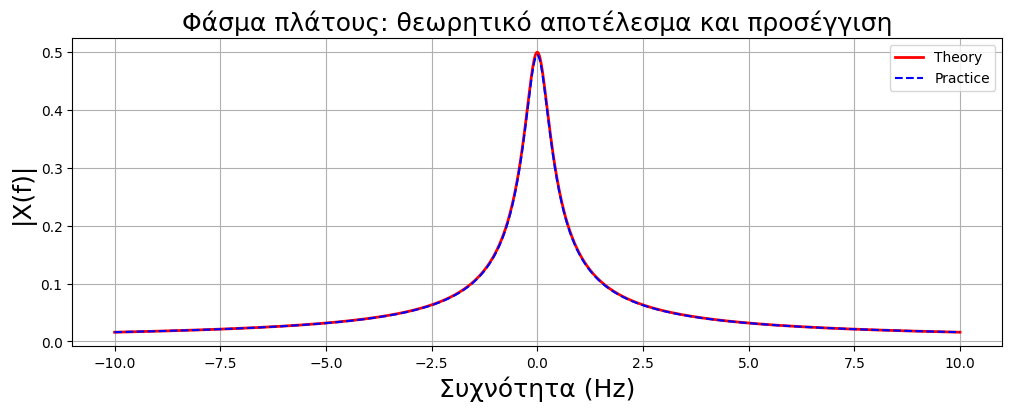

In [57]:
plt.figure(figsize=(12,4))
Xtheoretic = 1 / (a + 1j*2*np.pi*f)  
plt.plot(f, np.abs(Xtheoretic), 'r', linewidth=2, label="Theory")
plt.plot(f, np.abs(X), 'b--', linewidth=1.5, label="Practice")
plt.legend()
plt.title('Φάσμα πλάτους: θεωρητικό αποτέλεσμα και προσέγγιση', fontsize=18)
plt.xlabel("Συχνότητα (Hz)", fontsize=18)
plt.ylabel("|X(f)|", fontsize=18)
plt.grid()
plt.show()

**Εκπληκτικό**!! Η προσέγγισή μας είναι εξαιρετικά καλή, καθώς δεν μπορούμε εύκολα να διακρίνουμε τα δυο φάσματα πλάτους. Ας δούμε απλά πόσο είναι το σφάλμα σε κάθε συχνότητα αλλά και το μέγιστο σφάλμα μεταξύ τους:

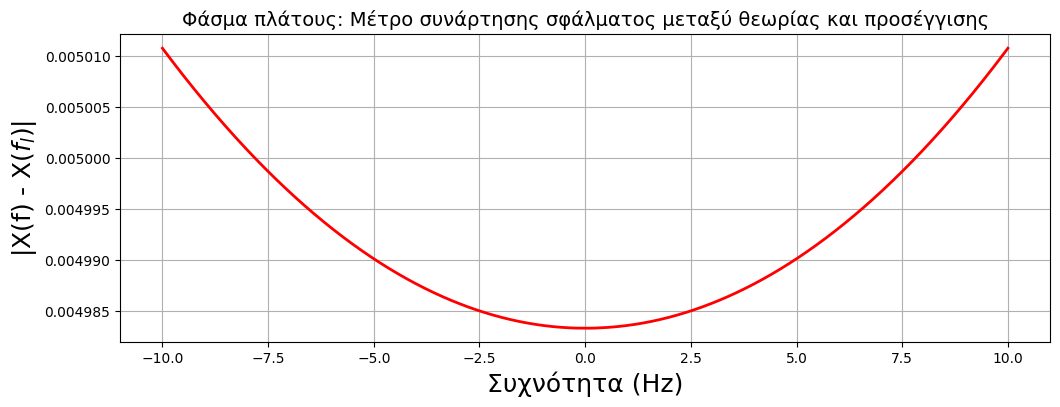

Το μέγιστο σφάλμα μεταξύ της θεωρίας και της προσέγγισης είναι 0.0050107963205422166


In [58]:
plt.figure(figsize=(12,4))
error = np.abs(Xtheoretic - X)
plt.plot(f, error, 'r', linewidth=2)
plt.title('Φάσμα πλάτους: Μέτρο συνάρτησης σφάλματος μεταξύ θεωρίας και προσέγγισης', fontsize=14)
plt.xlabel("Συχνότητα (Hz)", fontsize=18)
plt.ylabel("|X(f) - X($f_l$)|", fontsize=18)
plt.grid()
plt.show()

Max_error = np.max(np.abs(X-Xtheoretic))
print(f"Το μέγιστο σφάλμα μεταξύ της θεωρίας και της προσέγγισης είναι {Max_error}")

---


$\left(\beta'\right)$ Ας προσπαθήσουµε τώρα να συνθέσουµε το σήµα στο χρόνο µέσω του αντίστροφου µετασχηματισμού Fourier, δηλ. ας προσπαθήσουµε να βρούµε το σήµα στο χρόνο, $x(t)$, χρησιμοποιώντας το Μετασχ. Fourier! Ο µετασχ. Fourier που έχουµε βρει ορίζεται µόνο στο διάστηµα $f \in [−10, 10]$ Hz, ενώ έχουμε κάνει και δειγματοληψία ανά $0.01$ Hz στο διάστημα αυτό, αρα σίγουρα θα έχουµε κάποιο σφάλµα και στον υπολογισµό του $x(t)$.

Γνωριζοντας τα δείγµατα του χρόνου και της συχνότητας µπορούµε να κατασκευάσουµε το λεγόµενο $\textit{πίνακα σύνθεσης}$ του αντίστροφου µετασχ. Fourier:

$$\large M_{inv}(f_l, t_n) = e^{j2πf_l t_n}$$

με τους δείκτες $l, n$ να υποδεικνύουν ξανά ότι οι μεταβλητές αυτές είναι διακριτές: έχουμε λάβει μόνο κάποια δείγματα από τις συνεχείς μεταβλητές $f, t$.

In [59]:
# Έχουμε ήδη τακτοποιήσει τις επεκτάσεις των αξόνων t -> tt και f -> ff, οπότε δε χρειάζεται να το επαναλάβουμε.
# M_inv(f_l, t_n): Σύμφωνα με τη γραμμική άλγεβρα: [1000 x 1] * [1 x 2001] = [1000 x 2001]:
Minv = np.exp(1j * 2 * np.pi * tt.T @ ff)

Τώρα έχουμε τον πίνακα $M_{inv}(f_l, t_n)$, μεγέθους $1000$ x $2001$: έχουμε $1000$ δείγματα από τον άξονα του χρόνου και $2001$ δείγματα από τον άξονα συχνότητας (όπως και πριν), και έχουμε κατασκευάσει τα μιγαδικά εκθετικά μας σήματα $e^{j2\pi f_l t_n}$.

Για να υπολογίσουμε τον αντίστροφο μετασχηματισμό Fourier, θα δουλέψουμε όπως για το άθροισμα Riemann προηγουμένως, µε κάποιες μικρές διαφοροποιήσεις, δηλ. θα δημιουργήσουμε την προσέγγιση του αντίστροφου μετασχηματισμού Fourier ως:

$$\large x(t) = \int_{-\infty}^{+\infty} X(f)e^{j2\pi ft}df \approx \sum_{l=-\infty}^{+\infty} \left(X\left(f_l \right) e^{j2\pi t_n f_l} \Delta f\right) = \Delta f \cdot \mathbf{X} \cdot \mathbf{M_{inv}}^T$$


Η σύνθεση του σήματος στο χρόνο γίνεται ως:

In [60]:
XX = np.expand_dims(X, axis=0) # Επαναφέρουμε την έξτρα διάσταση που "κόψαμε" πριν για λόγους απεικόνισης.

x_est = Df * XX @ Minv.T       # Αντίστρ. M. Fourier: [1 x 2001] * [2001 x 1000] = [1 x 1000], όπως αναμενόταν.

x_est = x_est.real             # Λόγω αριθμητικών σφαλμάτων, θα υπάρχει ένα απειροελάχιστο φανταστικό μέρος στο αποτέλεσμα, το οποίο και απορρίπτουμε κρατώντας το πραγματικό μέρος μόνο - αφού γνωρίζουμε ότι το σήμα μας στο χρόνο είναι πραγματικό.

x_est = np.squeeze(x_est)      # "Κόβουμε" την έξτρα διάσταση όπως πριν για καλύτερη διαχείριση στα γραφήματα.

Ας συγκρίνουμε το αποτέλεσμά µας µε το θεωρητικό:

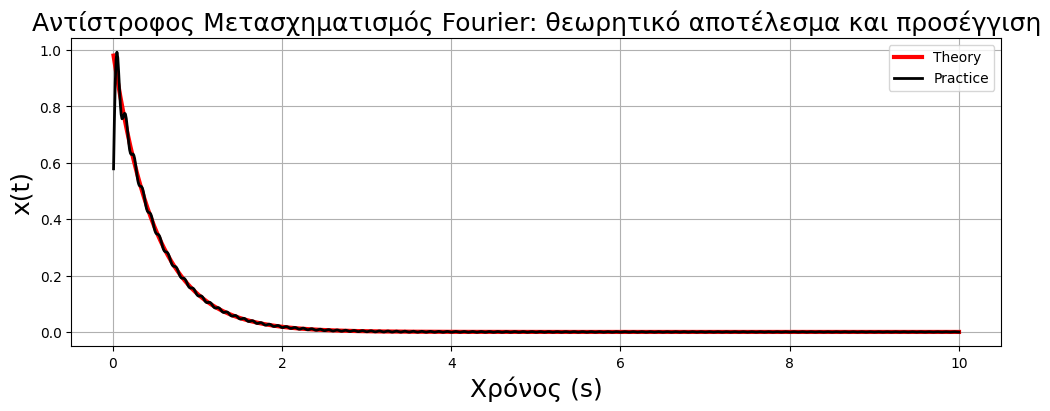

In [61]:
plt.figure(figsize=(12,4))
plt.plot(t, x, 'r', linewidth=3, label="Theory")
plt.plot(t, x_est, 'k', linewidth=2, label="Practice")
plt.title('Αντίστροφος Μετασχηματισμός Fourier: θεωρητικό αποτέλεσμα και προσέγγιση', fontsize=18)
plt.xlabel("Χρόνος (s)", fontsize=18)
plt.ylabel("x(t)", fontsize=18)
plt.legend()
plt.grid()
plt.show()

Εδώ η διαφορά είναι πιο εμφανής! Ας υπολογίσουμε κι εδώ το μέγιστο σφάλμα μεταξύ των δυο συναρτήσεων:

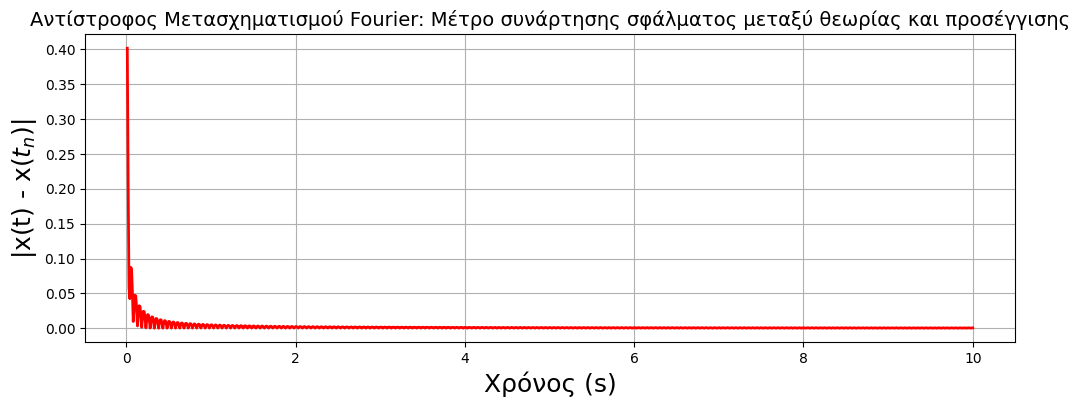

Το μέγιστο σφάλμα μεταξύ της θεωρίας και της προσέγγισης είναι 0.4016245695950722


In [62]:
plt.figure(figsize=(12,4))
error = np.abs(x-x_est)
plt.plot(t, error, 'r', linewidth=2)
plt.title('Αντίστροφος Μετασχηματισμού Fourier: Μέτρο συνάρτησης σφάλματος μεταξύ θεωρίας και προσέγγισης', fontsize=14)
plt.xlabel("Χρόνος (s)", fontsize=18)
plt.ylabel("|x(t) - x($t_n$)|", fontsize=18)
plt.grid()
plt.show()

Max_error = np.max(np.abs(x-x_est))
print(f"Το μέγιστο σφάλμα μεταξύ της θεωρίας και της προσέγγισης είναι {Max_error}")

---
---

Γράψτε κατάλληλο κώδικα για να βρείτε και τυπώσετε τα παρακάτω σήματα:

i. $x_1(t) = -e^{3t}u(-t)$

ii. $x_2(t) = 4\mathrm{rect}(t+1)$

iii. $x_3(t) = 2\mathrm{tri}(t-2)$

iv. $x_4(t) = e^{-|t|}$

**υλοποιώντας τα πρώτα στο πεδίο του χρόνου, βρίσκοντας το μετασχ. Fourier τους, και χρησιμοποιώντας τον για να ξανασυνθέσετε το σήμα στο χρόνο (ακριβώς όπως στο παραπάνω παράδειγμα)**. Σας δίνεται βοηθητικός κώδικας παρακάτω.

---

#### <span style="color:orange"> Σημείωση: Βοηθητικές συναρτήσεις:</span> 

Στην βιβλιοθήκη $\texttt{SciPy}$ παρέχονται υλοποιήσεις για τον τετραγωνικό και τριγωνικό παλμό (στο $\texttt{signal}$ υποπακέτο), αλλά θα σας φανούν λίγο περίεργες ως προς την χρήση τους. 

Προς ευκολία σας, σας δίνονται εναλλακτικές, απλούστερες υλοποιήσεις του τετραγωνικού και τριγωνικού παλμού που μοιάζουν πολύ με αυτές που έχουμε δει στο μάθημα. Έχουν ήδη γίνει ``import`` στο πρώτο κελί από το αρχείο ``utils.py`` που σας δίνουμε. Απλά δείτε το πως τις καλείτε.

In [63]:
help(rect)

Help on function rect in module utils:

rect(time_axis, dt, A=1, T=1, t_0=0)
    Παράμετροι:
    ----------
    time_axis: ndarray
        άξονας του χρόνου (χωρίς έξτρα διάσταση)
    dt: ndarray
        βήμα στο χρόνο 
    A: float
        πλάτος του τετραγωνικού παλμού 
    T: float
        διάρκεια ολόκληρου παλμού 
    t_0: float
        μετατόπιση: (καθυστέρηση για t_0>0, προήγηση για t_0<0)
    Επιστρέφει:
    -------
    ndarray
        rect(t/T) = {A, t στο (-T/2, T/2)
                    {0, αλλού.



In [64]:
help(tri)

Help on function tri in module utils:

tri(time_axis, dt, A=1, T=1, t_0=0)
    Παράμετροι:
    ----------
    time_axis: ndarray
        άξονας του χρόνου (χωρίς έξτρα διάσταση)
    dt: ndarray
        βήμα στο χρόνο 
    A: float
        πλάτος του τριγωνικού παλμού 
    T: float
        διάρκεια ΜΙΣΟΥ παλμού 
    t_0: float
        μετατόπιση: (καθυστέρηση για t_0>0, προήγηση για t_0<0)
    Επιστρέφει:
    -------
    ndarray
        Atri(t/T) = {A(1-|t|/T), t στο (-T, T)
                    {0, αλλού.



Επίσης, σας δίνονται ως συναρτήσεις οι παρακάτω δυο:
- $\texttt{ctft2ictft}$: υπολογίζει το σήμα στο χρόνο $x(t)$ μέσω του αντίστροφου μετασχ. Fourier, αξιοποιώντας το μετασχ. Fourier $X(f)$, εκτελώντας τα βήματα που είδατε πριν
- $\texttt{plotter}$: τυπώνει τη σύγκριση μεταξύ δυο σημάτων **στο χρόνο**: του αυθεντικού και της προσέγγισης μέσω αντιστρ. μετασχ. Fourier

Απλά δείτε πως συντάσσονται, καθώς κι αυτές έχουν γίνει ήδη ``import``.

In [65]:
help(ctft2ictft)

Help on function ctft2ictft in module utils:

ctft2ictft(freq, df, time, dt, xx)
    Continuous-Time FT to Inverse Continuous-Time FT
    
    Παράμετροι:
    ----------
    freq: ndarray
        άξονας της συχνότητας (χωρίς την έξτρα διάσταση)
    df: ndarray
        βήμα στη συχνότητα
    time: ndarray
        άξονας του χρόνου (χωρίς την έξτρα διάσταση)
    dt: ndarray
        βήμα στο χρόνο
    xx: ndarray
        σήμα στο χρόνο
    Επιστρέφει:
    -------
    x_inv: ndarray
        το σήμα στο χρόνο υπολογισμένο μέσω του μετασχηματισμού Fourier, ως αποτέλεσμα της ακολουθίας πράξεων: 
        
                                              xx(t) -> X(f) -> x_inv(t)



In [66]:
help(plotter)

Help on function plotter in module utils:

plotter(time, signal, signal_est, title)
    Παράμετροι:
    ----------
    time: ndarray
        άξονας του χρόνου (χωρίς την έξτρα διάσταση)
    signal: ndarray
        σήμα στο χρόνο (original) (χωρίς την έξτρα διάσταση)
    signal_est: ndarray
        σήμα στο χρόνο (προσέγγιση μέσω μετασχ. Fourier) (χωρίς την έξτρα διάσταση)
    title: string
        τίτλος γραφήματος
    Επιστρέφει:
    -------
    Γράφημα



---

Συμπληρώστε τον παρακάτω κώδικα:

In [67]:
# Χρησιμοποιήστε τις ακόλουθες μεταβλητές/διανύσματα για όλες τις απαντήσεις σας παρακάτω:
df = 0.01
f = np.arange(start=-10, stop=10+df, step=df)
dt = 0.01
# Ο άξονας του χρόνου t σας δίνεται για το κάθε παράδειγμα ...

i. $x_1(t) = -e^{3t}u(-t)$

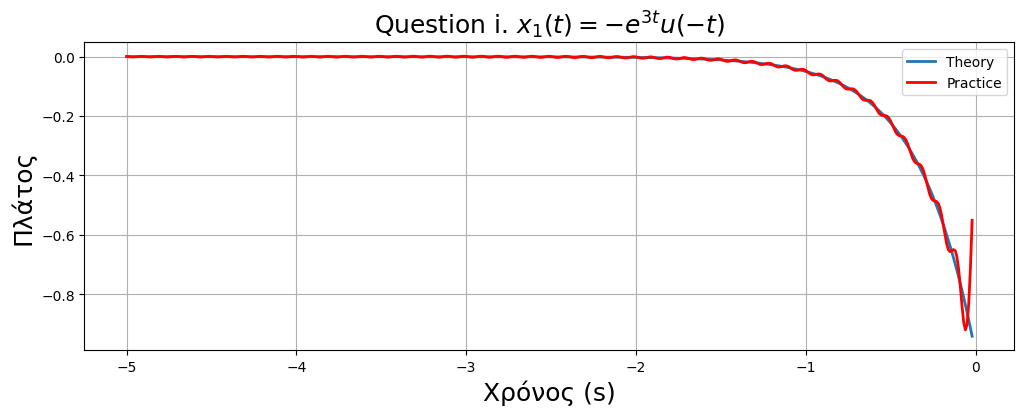

In [68]:
#  i)
t = np.arange(start=-5, stop=-dt, step=dt)
x1 = -np.exp(3 * t) 
x1_est = ctft2ictft(f, df, t, dt, x1)
plotter(time=t, signal=x1, signal_est=x1_est.real, title="Question i. $x_1(t)=-e^{3t}u(-t)$")

ii. $x_2(t) = 4\mathrm{rect}(t+1)$

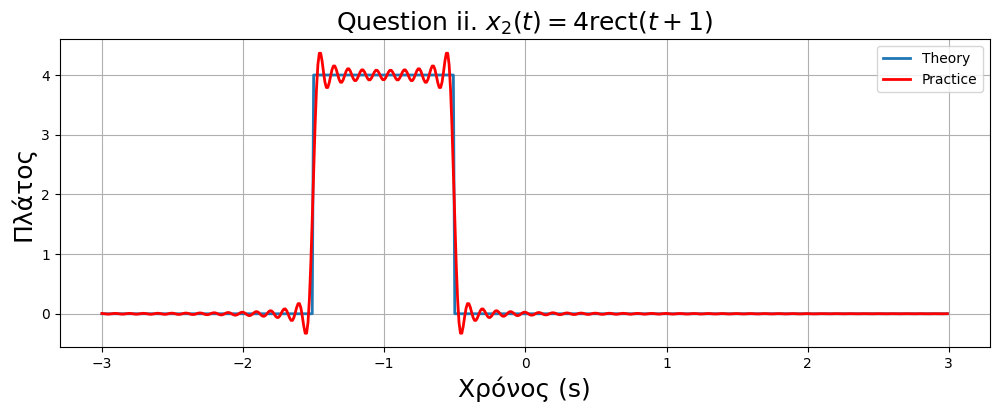

In [69]:
# ii)
t = np.arange(start=-3, stop=3, step=dt)
x2 = rect(t, dt, A=4, T=1, t_0=-1) 
x2_est = ctft2ictft(f, df, t, dt, x2)
plotter(time=t, signal=x2, signal_est=x2_est.real, title="Question ii. $x_2(t)=4\mathrm{rect}(t+1)$")

iii. $x_3(t) = 2\mathrm{tri}(t-2)$

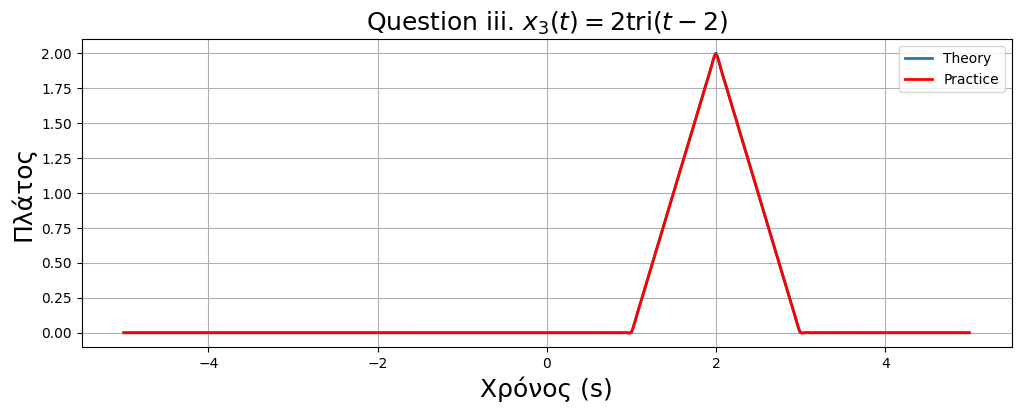

In [70]:
# iii)
t = np.arange(start=-5, stop=5, step=dt)
x3 = tri(t, dt, A=2, T=1, t_0=2)
x3_est = ctft2ictft(f, df, t, dt, x3)
plotter(time=t, signal=x3, signal_est=x3_est.real, title="Question iii. $x_3(t)=2\mathrm{tri}(t-2)$")

iv. $x_4(t) = e^{-|t|}$

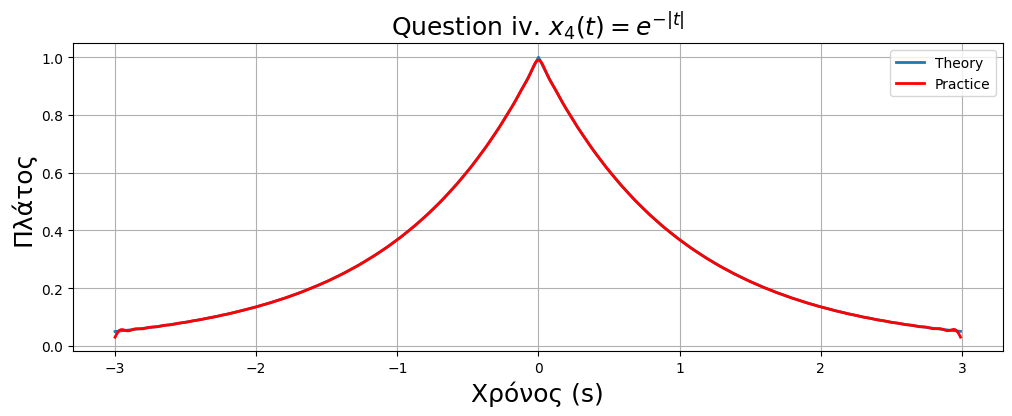

In [71]:
# iv)
t = np.arange(start=-3, stop=3, step=dt)
x4 = np.exp(-np.abs(t))
x4_est = ctft2ictft(f, df, t, dt, x4)
plotter(time=t, signal=x4, signal_est=x4_est.real, title="Question iv. $x_4(t)=e^{-|t|}$")

Αν τα κανετε όλα σωστά, θα πάρετε τα παρακάτω σχήματα:

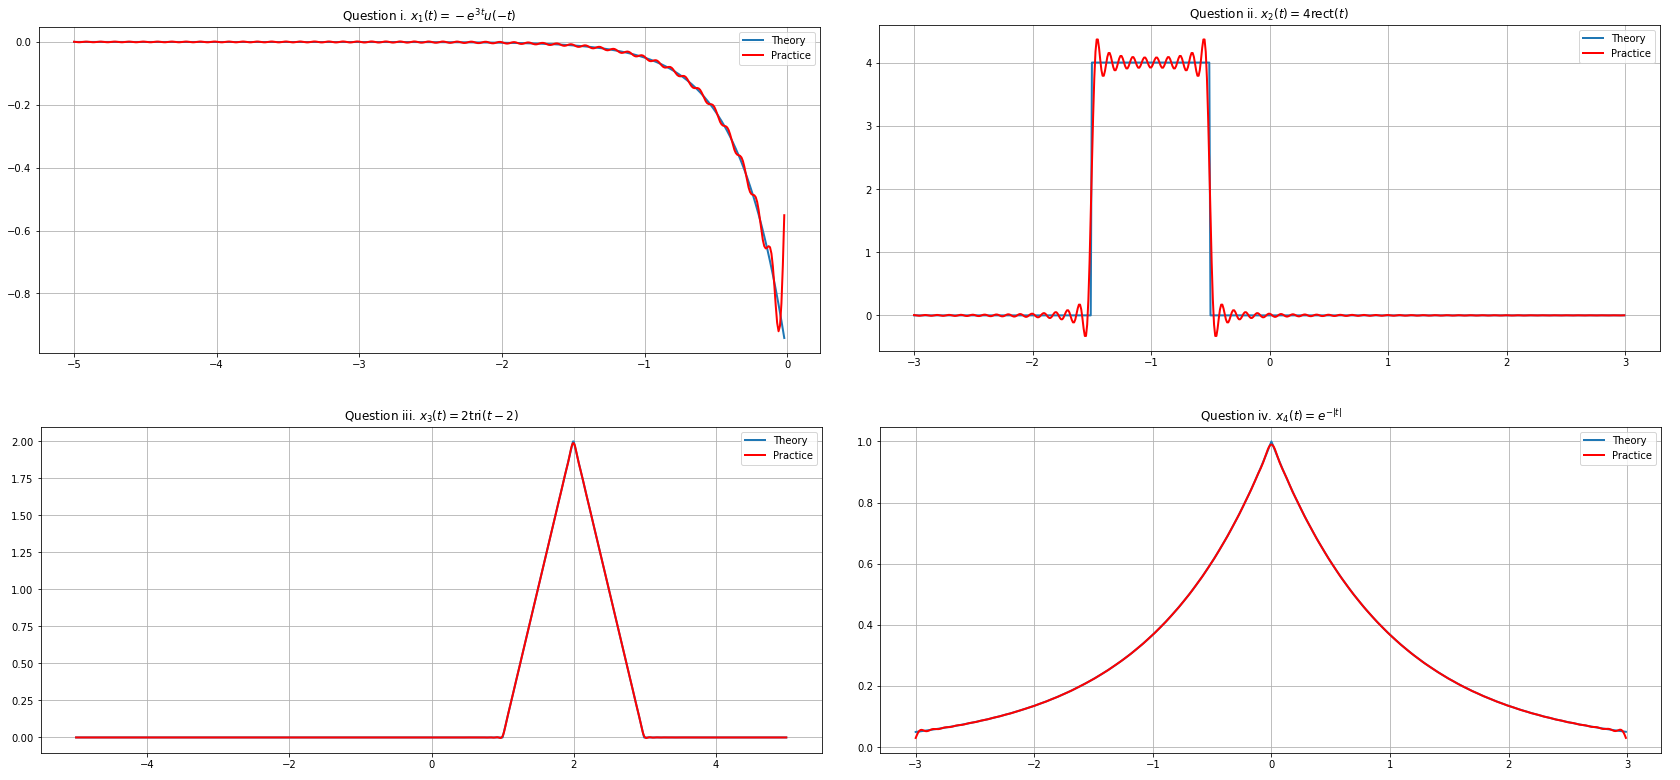

---
---

### Άσκηση 2: Μετασχηματισμός Fourier και Παθολογίες Φωνής

Ο μετασχηματισμός Fourier είναι ένα   **ασύλληπτα**   χρήσιμο εργαλείο σε πολλούς τομείς της Επεξεργασίας Σήματος. 

Ένας τέτοιος τομέας είναι η **ανίχνευση παθολογίας φωνής**.


Ηχογραφήστε τη φωνή σας όταν εκφέρετε το φώνημα /α/, σταθερά, για περίπου $3-4$ δευτερόλεπτα. Φροντίστε να βρίσκεστε σε ήσυχο περιβάλλον, και προσπαθήστε (αν γίνεται) να χρησιμοποιήσετε κανονικό μικρόφωνο (αλλιώς, χρησιμοποιήστε τα ενσωματωμένα των laptops σας). 

Χρησιμοποιήστε ένα πρόγραμμα ηχογράφησης της επιλογής σας (π.χ. το δωρεάν πρόγραμμα Wavesurfer ή το Audacity, που έχουμε προτείνει και σε προηγούμενο ερργαστήριο) και φροντίστε η ηχογράφηση να είναι μονοφωνική (δηλ. όχι στέρεο - δικαναλική) και να γίνει σε συχνότητα δειγματοληψίας $16000$ Hz, και ακρίβεια αποθήκευσης $16$ bits σε μορφή $\texttt{.wav}$. 

**Σας δίνεται και ένα ενδεικτικό σήμα μαζί με το εργαστήριο, αν δεν μπορέσετε να πραγματοποιήσετε τα παραπάνω.**

---

Χρησιμοποιήστε τον κώδικα ανάλυσης μετασχηματισμού Fourier που σας δόθηκε στην προηγούμενη άσκηση (και για ευκολία, σας δίνεται σε ξεχωριστό αρχείο ``utils.py`` ως συνάρτηση $\texttt{ctft}$) 

In [72]:
help(ctft)

Help on function ctft in module utils:

ctft(ss, tt, ff, plot=True)
    Συνάρτηση που υπολογίζει το μετασχ. Fourier ενός σήματος
    Ορίσματα: ss : σήμα στο χρόνο
              tt : άξονας χρόνου
              ff : άξονας συχνότητας
              plot = False: εκτύπωση σχημάτων
    Έξοδος: τρια σχήματα με το σήμα στο χρόνο, και τα δυο φάσματα
    ή
            τρια διανύσματα με το Μετασχ. Fourier, το μέτρο του, και τη συνάρτηση φάσης του



για να αναλύσετε το σήμα όπως περιγράφεται παρακάτω:



* Ας φορτώσουμε κι ακούσουμε την ηχογράφησή μας.

In [73]:
Fs, s = wav.read('alpha.wav')  # Φορτώστε το σήμα (alpha.wav, που σας δίνεται, ή όπως ονομάσατε αυτό που ηχογραφήσατε).
s = s / np.max(np.abs(s))      # Κανονικοποιήστε τα πλάτη στο [-1, 1].

print(f"Το σήμα μας περιέχει {s.shape[0]} το πλήθος δείγματα και έχει διάρκεια {s.shape[0]/Fs} sec!") # Δείτε πόσα δείγματα της φωνής μας περιέχονται στο διάνυσμα s!
Audio(s, rate=Fs)

Το σήμα μας περιέχει 41504 το πλήθος δείγματα και έχει διάρκεια 2.594 sec!


* Επιλέξτε ένα τμήμα (ή, όπως λέμε στην ορολογία της Επεξεργασίας Σήματος, ένα **παράθυρο**) φωνής, με διάρκεια περίπου $50$ ms, κατά προτίμηση από τη μέση περίπου της ηχογράφησης. Ουσιαστικά, αυτό που κάνετε τώρα είναι να **πολλαπλασιάστε ένα τετραγωνικό παλμό $rect()$ με ένα σήμα μεγαλύτερης διάρκειας**. Φυσικά δεν εκτελούμε ρητά τον πολλαπλασιασμό, καθώς το τετραγωνικό παράθυρο έχει μοναδιαία τιμή και δεν έχει νόημα να ξοδέψουμε πράξεις για να πολλαπλασιάσουμε τις τιμές του σήματος με τη μονάδα. Απλά θα κόψουμε ένα τμήμα του σήματος χρησιμοποιώντας δείκτες σε arrays. Στην ``Python``, αυτό μπορεί να γίνει ως:

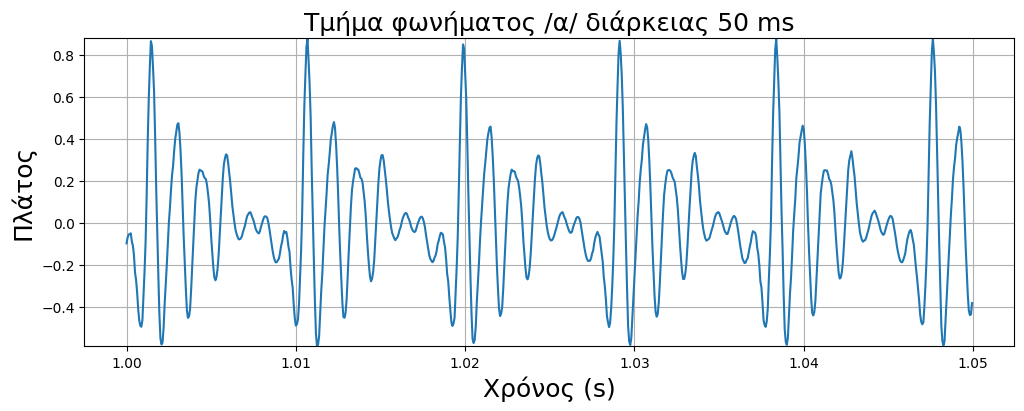

In [74]:
start = 1                                # Έστω ότι το τμήμα μας αρχίζει στο 1 sec...
finish = 1.05                            # ...και τελειώνει μετά από 0.05 sec = 50 ms.

start_s = round(start*Fs)                # Mετατρέπουμε την αρχή σε δείγματα.
finish_s = round(finish*Fs)              # Μετατρέπουμε το τέλος σε δείγματα.

segment = s[start_s:finish_s]            # "Κόβουμε"/απομονώνουμε το τμήμα που μας ενδιαφέρει από το αρχικό σήμα s.
t = np.arange(start_s, finish_s, 1)/Fs   # Άξονας του χρόνου (1, 1.05) s.

plt.figure(figsize=(12,4))               # Οπτικοποίηση...
plt.plot(t, segment)              
plt.ylim([min(segment), max(segment)])
plt.grid()
plt.title('Τμήμα φωνήματος /α/ διάρκειας 50 ms', fontsize=18)
plt.xlabel("Χρόνος (s)", fontsize=18)
plt.ylabel("Πλάτος", fontsize=18)
plt.show()

* Στη μεταβλητή ``segment`` έχετε ένα τμήμα της φωνής σας διάρκειας $50$ ms. Χρησιμοποιήστε τον κώδικα ανάλυσης Fourier (συνάρτηση ``ctft`` που έχει ήδη γίνει ``import`` για σας στο πρώτο κελί του εργαστηρίου) για να αναλύσετε το σήμα σας στην περιοχή συχνοτήτων από $2000$ ως $4000$ Hz και να βρείτε το μετασχηματισμό Fourier και να απεικονίστε γραφικά το φάσμα πλάτους και το φάσμα φάσης. H προαναφερθείσα συνάρτηση δέχεται τρια ορίσματα:

1. Το σήμα ομιλίας
2. Τον άξονα του χρόνου (σας δίνεται παρακάτω)
3. Τον άξονα της συχνότητας (πρέπει να τον κατασκευάσετε εσείς, με βάση την προηγούμενη περιγραφή)

* Στον κώδικα ανάλυσης, χρησιμοποιήστε μικρό βήμα στη συχνότητα, της τάξης του $0.1$ Hz, όπως σας δίνεται:

In [75]:
Df = 0.1                                             # Βήμα στη συχνότητα.
f = f = np.arange(start=2000, stop=4000+Df, step=Df) # - Κατασκευάστε τον άξονα συχνοτήτων από 2000 ως 4000 Hz (χρησιμοποιήστε τη συνάρτηση np.arange)...

* Αν το φάσμα πλάτους που θα δείτε, παρουσιάσει μια συμμετρία ως προς τη συχνότητα $3000$ Hz, τότε υπάρχει μια πιθανότητα $20\%$ να αναπτύξετε ασθένεια στο φάρυγγά σας τα επόμενα $5$ χρόνια. Προσέξτε λοιπόν να κάνετε σωστά την ανάλυση! 😁

In [76]:
t = np.arange(start=start_s, stop=finish_s, step=1)/Fs # Άξονας χρόνου.

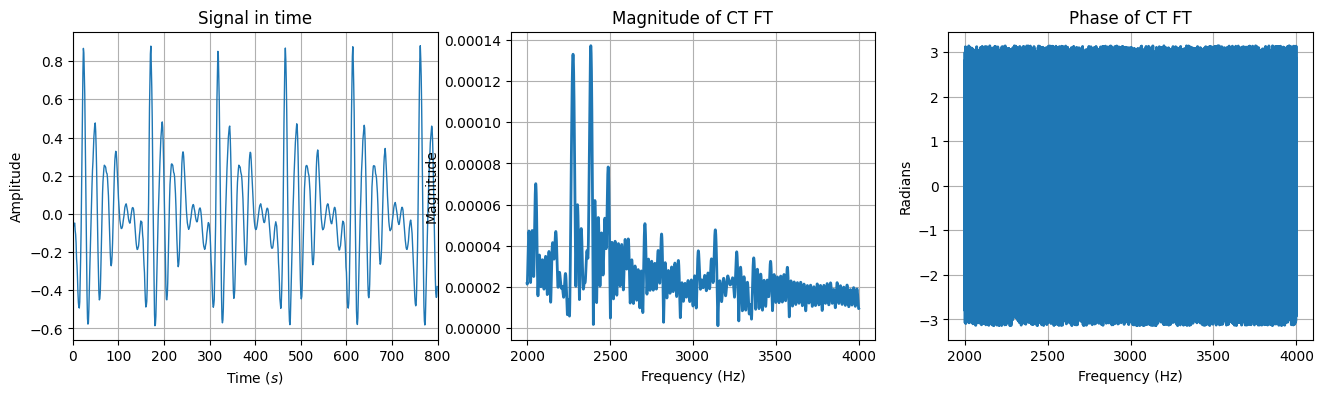

In [77]:
X, absX, angX = ctft(segment, t, f) # - Καλέστε τη συνάρτηση ctft με κατάλληλα ορίσματα...

Αν τα κάνετε όλα σωστά, θα πάρετε - για το δικό μας σήμα - ένα σχήμα όπως παρακάτω:

![alt text](HW3-FTpath_n.png "Title")

Παρατηρούμε ότι κάτι αχνοφαίνεται 😯 γύρω από τα $3000$ Hz (για το δικό μας σήμα - για το δικό σας? 😁) Απαντήστε παρακάτω:

???

---
---

### Άσκηση 3: Ευρωστία στην ανάλυση παθολογίας

Η άσκηση αυτή αποτελεί συνέχεια της προηγούμενης άσκησης σχετικά με παθολογία φωνής. 

Ίσως να σκεφτήκατε ότι αυτό που κάναμε στην προηγούμενη άσκηση, δηλ. το να πάρουμε ένα τυχαίο κομμάτι απ΄ το σήμα φωνής μας και αφού το αναλύσουμε, να βγάλουμε απόφαση για κάτι τόσο σοβαρό όπως μια πιθανή παθολογία, είναι λίγο ριψοκίνδυνο και επιπόλαιο. Κάτι πιο ασφαλές θα ήταν το εξής:

$\left(\alpha'\right)$ Χωρίστε όλο το σήμα σε παράθυρα διάρκειας $50$ ms, με μια επικάλυψη γειτονικών παραθύρων της τάξης του $50\%$, δηλ. ‘‘προχωράτε’’ το παράθυρό σας πάνω στο σήμα της φωνής κάθε $25$ ms, ώστε τα παράθυρά σας να επικαλύπτονται κατά μισό παράθυρο.

Αυτό μπορείτε να το κάνετε με χρήση βρόχων επανάληψης όπως τους γνωρίζετε από τη `C` (for, while) - δε διαφέρουν πολύ. Μπορείτε να τις Google-άρετε για να δείτε πως συντάσσονται. Σκεφτείτε οτι απλά πρέπει να διατρέχετε ένα πίνακα-γραμμή (που είναι το σήμα σας) ανά κάποιο αριθμό στοιχείων.

$\left(\beta'\right)$ Υπολογίστε τον μετασχηματισμό Fourier για τις συχνότητες $2000−4000$ Hz με ανάλυση $Df = 1$ Hz, και βρείτε το φάσμα πλάτους του κάθε παραθύρου. Αποθηκεύστε το φάσμα πλάτους κάθε παραθύρου σε μια γραμμή ενός πίνακα $X$. Αυτό μπορεί να γίνει ως εξής (**ο παρακάτω κώδικας *δεν* είναι εκτελέσιμος, σας δίνεται ως βοήθεια για παρακάτω**):

```
for i in range(nseg):                              # Για κάθε παράθυρο στο σήμα...
                                                   # Έστω segment η μεταβλητή που έχουμε αποθηκεύσει. 
                                                   # Το τρέχον παράθυρό μας.
                                                   
    M = np.exp(-1j*2*np.pi*ff.T@tt)                # Πίνακας ανάλυσης Fourier. 
    MF = (1/Fs)*segment@M.T                        # Μετασχηματισμός Fourier.
    Fasma_platous = np.abs(MF)                     # Φάσμα πλάτους του.
    Y[i, :] = Fasma_platous                        # Αποθήκευσή του σε μια λίστα.
```

$\left(\gamma'\right)$ Υπολογίστε το "**μέσο φάσμα πλάτους**", δηλ. μια μέση τιμή όλων των φασμάτων πλάτους που έχετε βρει, έτσι ώστε στο τέλος να έχουμε μόνο ένα φάσμα πλάτους που αποτελει το μέσο όρο όλων, και να αποφασίσετε για την παθολογία βάσει αυτού. Χρήσιμη θα σας φανεί η εντολή $\texttt{mean}$ της $\texttt{NumPy}$.

Ακολουθώντας μια τέτοια διαδικασία έχουμε πιο εύρωστα, με τη στατιστική έννοια, συμπεράσματα.

Ας φορτώσουμε το σήμα μας.

In [78]:
Fs, s = wav.read('alpha.wav')   # Φορτώστε το αρχείο ήχου.
s = s / np.max(np.abs(s))       # Κανονικοποίηση.
L = len(s)                      # Διάρκεια του σήματος σε δείγματα.

Ας ορίσουμε τις παραμέτρους της ανάλυσής μας.

In [79]:
winlen_ms = 50e-3 # ms                # Έστω ότι το παράθυρό μας είναι 50 ms.
winlen = int(round(winlen_ms * Fs))   # Η διάρκειά του σε δείγματα.
overlap = int(winlen/2)               # Επικάλυψη κατά 50% των διαδοχικών παραθύρων.

Ας ξεκινήσουμε τη διαδικασία που περιγράψαμε παραπάνω.

In [80]:
Df = 1                                              # Βήμα στη συχνότητα.
f = np.arange(start=2000, stop=4000+Df, step=Df)    # Άξονας συχνότητας.
ff = np.expand_dims(f, axis=0)                      # Επέκταση διάστασης όπως αναφέραμε στην 1η άσκηση Python.
t = np.arange(start=0, stop=winlen_ms, step=1/Fs)   # Άξονας χρόνου για ένα παράθυρο διάρκειας 50ms.
tt = np.expand_dims(t, axis=0)                      # Επέκταση διάστασης όπως αναφέραμε στην 1η άσκηση Python.

N = int((L - winlen)/overlap)                       # Πλήθος frames που υπάρχουν στο σήμα μας.
Y = np.zeros(shape=(N, len(f)))                     # Δέσμευση μνήμης (όπως η calloc στη C).

for i in range(N):                                  # Βρόχος επανάληψης που διατρέχει τα frames του σήματος.
    start = overlap * i                             # Έναρξη παραθύρου - χρησιμοποιήστε τη μεταβλητή overlap και το δείκτη i.
    stop = i * overlap + winlen                     # Τέλος παραθύρου.
    segment = s[start:stop]                         # Αποκόπτουμε από το συνολικό σήμα s το κομμάτι που μας ενδιαφέρει - κάντε χρήση των start και stop επάνω στο διάνυσμα s, θυμηθείτε πώς κάνουμε slicing ένα array στην Python.
    M = np.exp(-1j * 2 * np.pi * ff.T @ tt)         # Πίνακας αναλυσης M(f,t) - όπως τον δείξαμε στην 1η άσκηση του εργαστηρίου.
    MF = (1/Fs) * segment @ M.T                     # Μετασχ. Fourier (όπως τον δείξαμε στην 1η άσκηση του εργαστηρίου).
    Y[i, :] = np.abs(MF)                            # Συλλέγουμε τα φάσματα πλάτους στον πίνακα Y, ένα σε κάθε θέση-γραμμή i του πίνακα.

Έχοντας μαζέψει όλα τα φάσματα πλάτους στον πίνακα Υ, ένα φάσμα σε κάθε γραμμή του, μπορούμε να υπολογίσουμε τη μέση τιμή όλων των φασμάτων πλάτους!

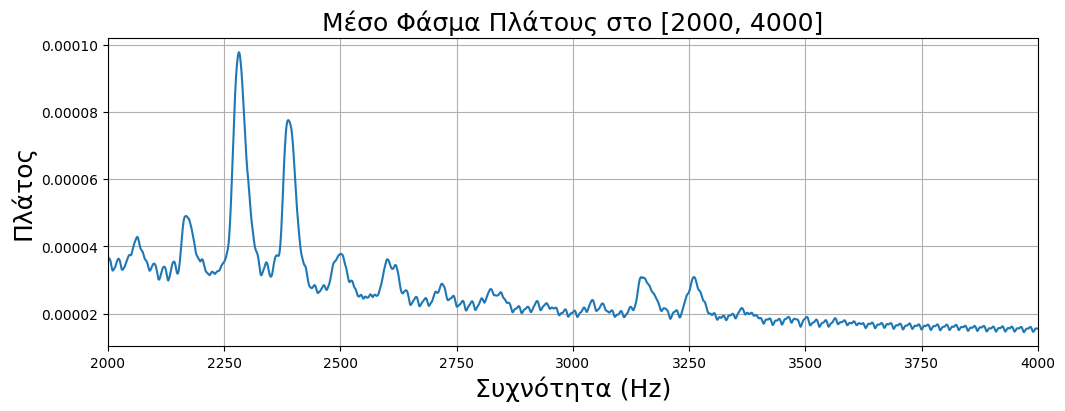

In [81]:
meanY = np.mean(Y, axis=0) # Υπολογίζουμε τη μέση τιμή των φασμάτων πλάτους - χρησιμοποιήστε την np.mean(..., axis=0).

plt.figure(figsize=(12,4))
plt.plot(f, meanY)
plt.xlim([f[0], f[-1]])
plt.grid()
plt.xlabel("Συχνότητα (Hz)", fontsize=18)
plt.ylabel("Πλάτος", fontsize=18)
plt.title('Μέσο Φάσμα Πλάτους στο [2000, 4000]', fontsize=18)
plt.show()

Αν τα κάνετε όλα σωστά, θα πάρετε - για το δικό μας σήμα - ένα σχήμα όπως παρακάτω:

![alt text](HW3-FTpath2.png "Title")

Παρατηρούμε ότι τελικά 😌 δεν υπάρχει ιδιαίτερη συμμετρία γύρω από τα $3000$ Hz (για το δικό μας σήμα - για το δικό σας? 😁) Απαντήστε παρακάτω:

- Απάντηση: όντως, ούτε στο δικό μας σήμα υπάρχει ιδιαίτερη συμμετρία γύρω απο τα 3000 Hz ...

---
---

### Άσκηση 4: Αποθορυβοποίηση Μουσικής

Στην άσκηση αυτή σας δίνεται ένα σήμα μουσικής $\texttt{sample-noise.wav}$. Πρόκειται για ένα γνωστό τραγούδι "μολυσμένο" με ένα ισχυρό σήμα ημιτόνου σε κάποια υψηλή, σταθερή, συχνότητα μεταξύ $2000$ και $3000$ Hz. Σκοπός της άσκησης είναι να αναλύσετε το σήμα και να αφαιρέσετε το θόρυβο. Ακολουθήστε τα παρακάτω βήματα.

$\left(\alpha'\right)$ Αρχικά, ακούστε το σήμα:

In [82]:
fs, y = wav.read("sample-noise.wav") # Φορτώνουμε το σήμα μας
Audio(y, rate=fs)

Ας το απεικονίσουμε:

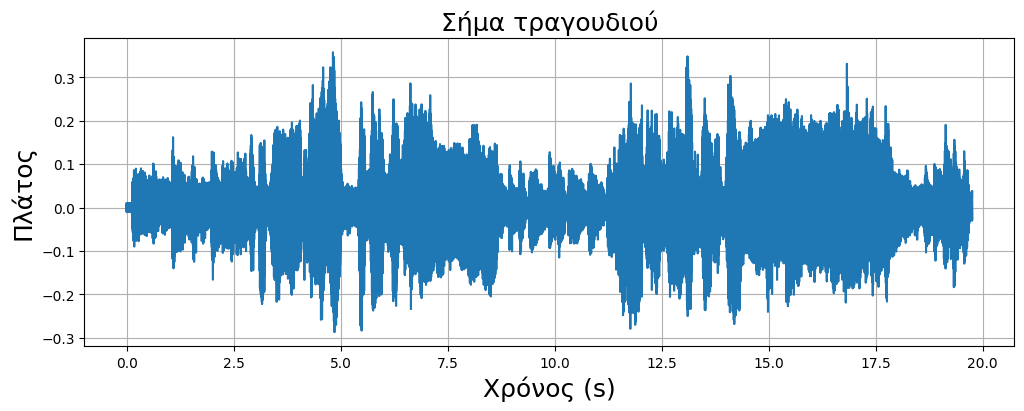

In [83]:
max_nb_bit = float(2 ** (16 - 1))                  # Κανονικοποίηση.
s = y / (max_nb_bit + 1)                           # ------ " ------
t = np.arange(start=0, stop=len(s)/fs, step=1/fs)  # Άξονας του χρόνου (για απεικόνιση).

plt.figure(figsize=(12,4))
plt.plot(t, s)
plt.grid()
plt.xlabel('Χρόνος (s)', fontsize=18)
plt.ylabel('Πλάτος', fontsize=18)
plt.title('Σήμα τραγουδιού', fontsize=18)
plt.show()

$\left(\beta'\right)$ Ακούστε (κάντε το $1-2$ φορές για να βεβαιωθείτε) ότι η συνιστώσα του ημιτόνου είναι ισχυρή, και εύκολα διακρίνεται μέσα στον ήχο της ηχογράφησης. Γνωρίζετε όμως ότι λόγω της ισχύος της, θα πρέπει να "ξεχωρίζει" σχετικά στο φάσμα πλάτους του σήματος απο το υπόλοιπο σήμα. Επίσης, επειδή είναι σταθερής συχνότητας συνιστώσα, μπορούμε να την εντοπίσουμε σε κάποια σημεία (παράθυρα) του σήματος (αν δεν επικαλύπτεται από άλλες συχνότητες). Από τις διαλέξεις ξέρετε ότι ένα ημίτονο συχνότητας $f_0$ έχει μετασχ. Fourier δυο συναρτήσεις Δέλτα στις συχνότητες $\pm f_0$. Αυτό το αποτέλεσμα όμως αφορά άπειρης διάρκειας ημίτονα: για πεπερασμένης διάρκειας ημίτονα, ο μετασχ. Fourier εξαρτάται από το μετασχ. Fourier του τετραγωνικού παραθύρου που χρησιμοποιείτε έμμεσα όταν έχετε ένα τμήμα ενός σήματος. Αυτό σημαίνει ότι αντί των συναρτήσεων Δέλτα θα αναμένετε να δείτε στο φάσμα πλάτους κάτι που να μοιάζει με τον κεντρικό λοβό της συνάρτησης $\mathrm{sinc()}$!

$\left(\gamma'\right)$ Στον κώδικα που ακολουθεί, θα διαλέξετε ένα τυχαίο παράθυρο σήματος, διάρκειας $30$ ms και θα το αναλύσετε στις παραπάνω συχνότητες [$2000, 3000$] Hz με τον μετασχηματισμό Fourier, χρησιμοποιώντας φυσικά το φάσμα πλάτους. Προσπαθήστε να εντοπίσετε το ημίτονο αναζητώντας μια ισχυρή συνιστώσα σε κάποια συχνότητα.

Όπως προναφέρθηκε, σκεφτείτε ότι ο μετασχηματισμός Fourier του ημιτόνου πλησιάζει το αποτέλεσμα δυο συναρτήσεων Δέλτα που έχουν γίνει συνέλιξη με το μετασχηματισμό Fourier του παραθύρου σας (δείτε τις διαφάνειες των ιδιοτήτων του μετασχ. Fourier, και συγκεκριμένα την ιδιότητα του πολλαπλασιασμού στο χρόνο). Πρακτικά, θα περιμένετε να δείτε κάποιο ισχυρό peak (κορυφή που μοιάζει με τον κεντρικό λοβό της συνάρτησης $\mathrm{sinc()}$) στο φάσμα πλάτους. Όμως επειδή το περιεχόμενο του σήματος είναι μουσική και φωνή, το φάσμα πλάτους θα περιέχει και άλλες ισχυρές συχνότητες. Οπότε η αναγνώριση του peak από ένα και μόνο παράθυρο δεν αρκεί. 

### Προς διευκόλυνσή σας, δίνεται οτι η συχνότητα που ψάχνετε είναι $\textit{ακέραιος αριθμός}$, ακέραιο πολλαπλάσιο των $100$ Hz, στο διάστημα $[2000, 3000]$ Hz.

Ας πάρουμε ένα τυχαίο παράθυρο και να δούμε τι βρίσκουμε.

**Σημείωση:** Σε σχέση με τις προηγούμενες δυο ασκήσεις ``Python`` της σειράς αυτής, στην πραγματική ρέουσα ομιλία και στον ήχο, το σήμα αλλάζει πιο γρήγορα απ΄ ότι όταν λέμε ένα απλό /α/. Έτσι, χρησιμοποιούμε μικρότερο παράθυρο ανάλυσης ($30$ ms αντί για $50$ ms) για να είμαστε σχετικά ασφαλείς ότι το περιεχόμενό αυτού του παραθύρου δεν αλλάζει σημαντικά.

Η συχνότητα με το μέγιστο πλάτος στο παράθυρο αυτό είναι η = 2506 Hz


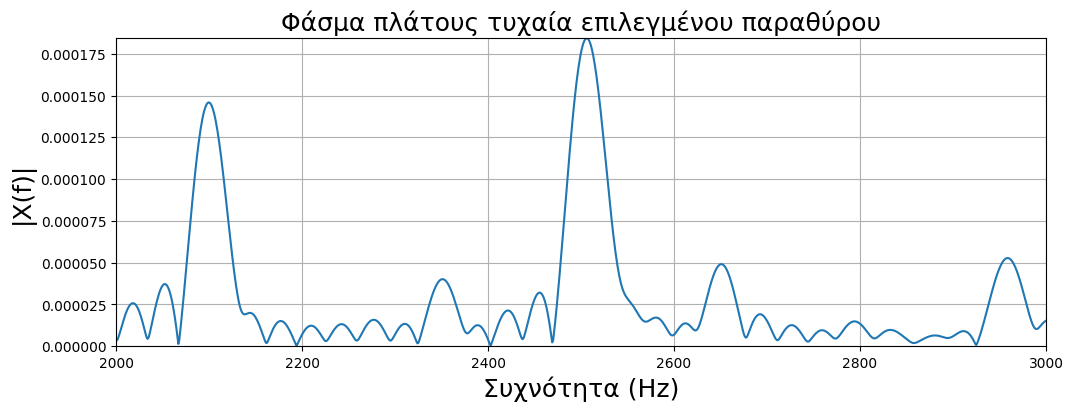

In [84]:
Df = 1                                                # Βήμα στη συχνότητα.
f = np.arange(start=2000, stop=3000+Df, step=Df)      # Άξονας συχνότητας στο διάστημα [2000,3000] Hz με βήμα Df=1 Hz.
ff = np.expand_dims(f, axis=0)                        # Επέκταση του άξονα όπως έχουμε δείξει στην 1η άσκηση Python.

winlen_ms = 30e-3                                     # Διάρκεια παραθύρου σε sec.
winlen = round(winlen_ms * fs)                        # Διάρκεια παραθύρου σε δείγματα - χρησιμοποιήστε τη round() και τη συχνότητα δειγνατοληψίας fs.

t = np.arange(start=0, stop=winlen_ms, step=(1/fs))   # O άξονας του χρόνου, διάρκειας 30ms, με βήμα dt=1/fs.
tt = np.expand_dims(t, axis=0)                        # Επέκταση του αξονα όπως έχουμε δείξει στην 1η άσκηση Python.

rng_idx = 43484                                       # Επιλέγουμε ένα τυχαίο δείγμα για να ξεκινήσουμε την αποκοπή.

start = rng_idx                                       # Η αρχή του παραθύρου μας.
stop = start + winlen                                 # Το τέλος του παραθύρου μας.
seg = s[start:stop]                                   # Το τυχαίο παράθυρο που επιλέξαμε από το σήμα s, που ξεκινά από το δείγμα start και τελειώνει στο δείγμα stop.

M = np.exp(-1j * 2 * np.pi * ff.T @ tt)               # Πίνακας ανάλυσης Fourier M(f,t) - όπως τον έχετε δει στις προηγούμενες ασκήσεις.

MF = (1/fs) * seg @ M.T                               # Μετασχ. Fourier.

Fasma_Platous = np.abs(MF)                            # Φάσμα πλάτους.

peak_idx = np.argmax(Fasma_Platous)                   # Συχνότητα που αντιστοιχεί στη μέγιστη τιμή του φάσματος πλάτους.
print(f"Η συχνότητα με το μέγιστο πλάτος στο παράθυρο αυτό είναι η = {f[peak_idx]} Hz")

plt.figure(figsize=(12,4))                            # Γράφημα.
plt.plot(f, Fasma_Platous)                                         
plt.xlim([f[0], f[-1]])
plt.grid()
plt.xlabel('Συχνότητα (Hz)', fontsize=18)
plt.ylabel('|X(f)|', fontsize=18)
plt.title('Φάσμα πλάτους τυχαία επιλεγμένου παραθύρου', fontsize=18)
plt.ylim([0, max(Fasma_Platous)])       
plt.show()                           

$\left(\delta'\right)$ Επιλέξτε διάφορα παράθυρα μέσα στο σήμα (ας πούμε $12$), όλα ίδιας διάρκειας, μέχρι να εντοπίσετε τη συχνότητα του ημιτόνου με κάποια βεβαιότητα. Για κάθε plot που κάνετε, μπορείτε να τυπώσετε την μέγιστη τιμή του φάσματος μέσω της συνάρτησης $\texttt{argmax}$ της $\texttt{NumPy}$ η οποία σας επιστρέφει το **index** της μέγιστης αυτής τιμής. Έτσι, μπορείτε να βρίσκετε εύκολα τη συχνότητα ενός σημείου στο φάσμα σας.

Η συχνότητα με το μέγιστο πλάτος είναι η = 2500 Hz


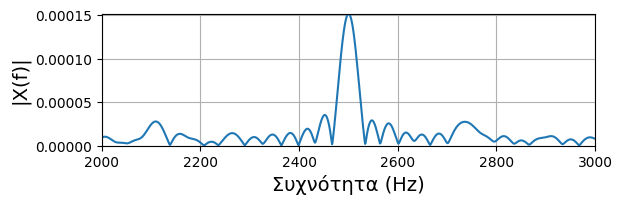

Η συχνότητα με το μέγιστο πλάτος είναι η = 2499 Hz


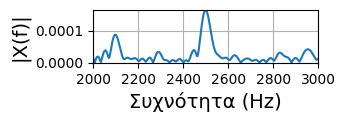

Η συχνότητα με το μέγιστο πλάτος είναι η = 2499 Hz


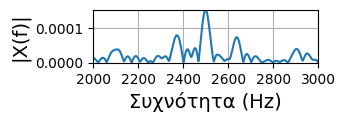

Η συχνότητα με το μέγιστο πλάτος είναι η = 2502 Hz


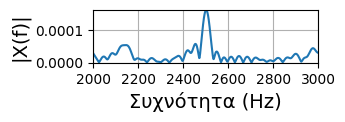

Η συχνότητα με το μέγιστο πλάτος είναι η = 2498 Hz


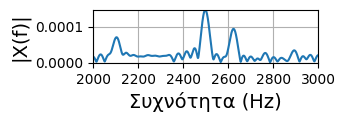

Η συχνότητα με το μέγιστο πλάτος είναι η = 2396 Hz


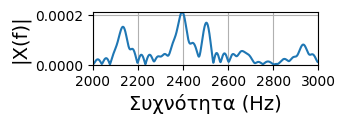

Η συχνότητα με το μέγιστο πλάτος είναι η = 2505 Hz


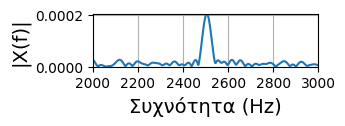

Η συχνότητα με το μέγιστο πλάτος είναι η = 2499 Hz


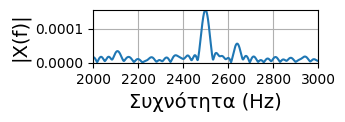

Η συχνότητα με το μέγιστο πλάτος είναι η = 2401 Hz


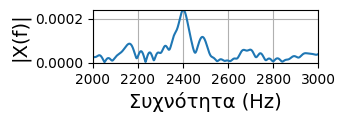

Η συχνότητα με το μέγιστο πλάτος είναι η = 2500 Hz


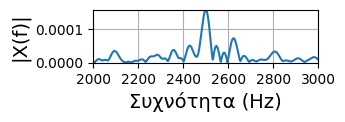

Η συχνότητα με το μέγιστο πλάτος είναι η = 2500 Hz


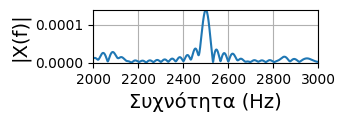

Η συχνότητα με το μέγιστο πλάτος είναι η = 2388 Hz


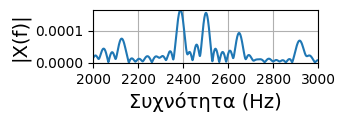

In [85]:
num_windows = 12                                                            # Πόσα τυχαία παράθυρα θέλουμε να επιλέξουμε? Έστω 12.
Y = np.zeros(shape=(num_windows, len(f)))                                   # Δέσμευση μνήμης (όπως η calloc στη C).
plt.figure(figsize=(14,12))                                                 # Γράφημα (δηλώνουμε το μέγεθος από τώρα).

for i in range(num_windows):                                                # Για κάθε παράθυρο από τα num_windows (= 12)...
    # Για να μην επιλέγουμε με το χέρι τα τυχαία τμήματα του σήματος, χρησιμοποιούμε μια γεννήτρια τυχαίων αριθμών...
    # Επιλέγουμε ένα τυχαίο δείγμα για να ξεκινήσουμε την αποκοπή. Το τυχαίο δείγμα έχουμε φροντίσει να ανήκει στο εύρος δειγμάτων του σήματος μας..
    rng_idx = np.random.randint(low=0, high=len(s)-winlen-1)

    start = rng_idx                                                         # Η αρχή του παραθύρου μας.
    stop = start+winlen                                                     # Το τέλος του παραθύρου μας.
    seg = s[start:stop]                                                     # Το τυχαίο παράθυρο που επιλέξαμε, όπως προηγουμένως.

    M = np.exp(-1j * 2 * np.pi * ff.T @ tt)                                 # Πίνακας ανάλυσης Fourier M(f,t).
    MF = (1/fs)*seg @ M.T                                                   # Μετασχ. Fourier.
    Fasma_Platous = np.abs(MF)                                              # Φάσμα πλάτους.
    
    peak_idx = np.argmax(Fasma_Platous)                                     # Συχνότητα που αντιστοιχεί στο μέγιστο πλάτος (μεγαλύτερο peak) του φάσματος.
    print(f"Η συχνότητα με το μέγιστο πλάτος είναι η = {f[peak_idx]} Hz")   # Εκτύπωση της συχνότητας αυτής.

    plt.subplot(num_windows//2, 2, i+1)
    plt.plot(f, Fasma_Platous)                                         
    plt.xlim([f[0], f[-1]])
    plt.grid()
    plt.xlabel('Συχνότητα (Hz)', fontsize=14)
    plt.ylabel('|X(f)|', fontsize=14)
    plt.ylim([0, max(Fasma_Platous)])         
    plt.show()                 

#### Από τα παραπάνω σχήματα και το output του κώδικα, ποιά πιστεύετε ότι είναι η συχνότητα του ημιτόνου που έχει "μολύνει" το σήμα μας? (θυμηθείτε, η συχνότητα που ψάχνουμε είναι ακέραιος αριθμός πολλαπλάσιος του 100 Hz στο [2000, 3000]!)

#### Γράψτε τη κάνοντας διπλό κλικ στο παρακάτω κελί:

* $f_0 = 2500 Hz$

$\left(\epsilon'\right)$ Σας δίνουμε επιπλέον ότι το ισχυρό αυτό ημίτονο έχει πλάτος $A = 0.01$ και αρχική φάση $\phi = 0$, δηλ. είναι της μορφής:

$$\large n(t) = A\cos\left(2\pi f_0 t + \phi \right) = 0.01\cos\left(2\pi f_0 t\right)$$

με $f_0$ τη **συχνότητα που μόλις βρήκατε παραπάνω**.

Δημιουργήστε ένα ημίτονο στην `Python` με πλάτος και φάση που σας δίνεται παραπάνω, και με συχνότητα αυτήν που βρήκατε από την ανάλυσή σας στο προηγούμενο ερώτημα. Φροντίστε να έχει ίδια διάρκεια με ολόκληρο το σήμα $\texttt{s}$ του τραγουδιού. Για να βρείτε τη διάρκεια αυτή, χρησιμοποιήστε τη συνάρτηση $\texttt{len}()$. 

In [86]:
# Ημίτονο-toy:
# Για παράδειγμα, αν θέλετε να φτιάξετε ενα ημίτονο διάρκειας 100 δειγμάτων, 
# δηλ. 100/16000 = 0.00625 δευτερολέπτων (με συχνότητα δειγματοληψίας 16000 Hz), πλάτους 1 
# και συχνότητας 200 Hz, θα κάνετε το εξής :
A = 1
f0 = 200
ffs = 16000
n_toy = A*np.cos(2*np.pi*(f0/ffs)*np.arange(100))

# Φτιάξτε εδώ το δικό σας ημίτονο, με τα χαρακτηριστικά που αναφέρονται στο ερώτημα (ε') παραπάνω:
A = 0.01
f0 = f[np.argmax(np.mean(Y, axis=0))]
ffs = 16000
n = A * np.cos(2 * np.pi * (f0/ffs) * np.arange(len(s)))

$\left(\sigma\tau'\right)$ Αφαιρέστε το σήμα ημιτόνου που φτιάξατε παραπάνω από το σήμα της ηχογράφησης $\texttt{s}$, απλώς αφαιρώντας μεταξύ τους το διάνυσμα s και το διάνυσμα ημιτόνου που μόλις φτιάξατε, όπως παρακάτω. Ακούστε το αποτέλεσμα. Θα πρέπει να ακούγεται πλέον καθαρό το σήμα.

In [87]:
Audio(s, rate=ffs)   # Πριν τον καθαρισμό...

In [88]:
clean_sig = s - n
Audio(clean_sig, rate=ffs)   # Μετά τον καθαρισμό...

**Σημείωση**: Το παραπάνω παράδειγμα ήταν πολύ "εκπαιδευτικό" 😁. Στην πράξη, το ημίτονο μπορεί να μην έχει σταθερό πλάτος ή μηδενική φάση, ή ακόμα κι αν έχει, δεν μπορούμε να γνωρίζουμε εκ των προτέρων τις τιμές τους. Έτσι, μια μέθοδος όπως η παραπάνω, στο πεδίο του χρόνου δηλαδή, δε ϑα δουλέψει - και σχεδόν ποτέ δεν εκτελούμε την αποθορυβοποίηση με αυτόν τον τρόπο.

Συνήθως χρησιμοποιούμε μεθόδους στο χώρο της συχνότητας για να αφαιρέσουμε τον ενοχλητικό θόρυβο, εφαρμόζοντας τα λεγόμενα **notch φίλτρα**, τα οποία είναι ΓΧΑ συστήματα που μηδενίζουν το πλάτος μιας συγκεκριμένης συχνότητας από ένα σήμα που δέχονται ως είσοδο. Ίσως τα δούμε σε επόμενο εργαστήριο.

---
---

### Άσκηση 5: Ανάλυση Ηλεκτροεγκεφαλογραφήματος

Ο μετασχ. Fourier έχει εκπληκτικές εφαρμογές στη Βιοϊατρική, και συγκεκριμένα στην Ηλεκτροεγκεφαλογραφία. 

Τοποθετώντας ηλεκτρόδια σε διάφορες περιοχές της κεφαλής ανιχνεύουμε ηλεκτρικές δραστηριότητες (διαφορές δυναμικού) οι οποίες θεωρείται ότι αποτελούν μια έκφραση της εγκεφαλικής δραστηριότητας. Τέτοιες καταγραφές έχουν γίνει τόσο κατά το στάδιο του ύπνου όσο και κατά τη διάρκεια κάποιας έντονης δραστηριότητας (π.χ., όταν προσπαθείτε να λύσετε τις ασκήσεις στο ΗΥ215 😁 ). Από κάθε ηλεκτρόδιο (σε συνδυασμό με ένα ηλεκτρόδιο αναφοράς) συλλέγουμε ένα σήμα όπου παρατηρούμε διαφορές δυναμικού $\Delta V$ μεταξύ των δυο.

Ένα σοβαρό πρόβλημα είναι η ανίχνευση των συχνοτήτων που υπάρχουν σε αυτές τις καταγραφές. Σε ορισμένες συχνότητες έχουμε αντιστοιχίσει κάποιους $\textit{ρυθμούς}$, όπως ονομάζονται, και οι οποίοι σηματοδοτούν κάτι ενδιαφέρον για την εγκεφαλική μας δραστηριότητα. Για παράδειγμα, η συχνότητα των $10$ Hz αντιστοιχεί στο λεγόμενο **ρυθμό Άλφα**.

Σας δίνουμε δυο καταγραφές διάρκειας ενός δευτερολέπτου η καθεμία. Η καταγραφή των δεδομένων έγινε λαμβάνοντας ένα δείγμα του σήματος συνεχούς χρόνου ανά $0.01$ δευτερόλεπτα. Ζητάμε να ελέγξετε αν αυτά τα σήματα έχουν ρυθμό Άλφα στο συχνοτικό τους περιεχόμενο (δηλ., αν έχουν ισχυρή φασματική συνιστώσα στα $10$ Hz). Οι ρυθμοί εμφανίζονται συνήθως στο εύρος συχνοτήτων $[3, 20]$ Hz, άρα θα στοχεύσουμε σε αυτό το διάστημα.

Για να εισάγετε τα δυο σήματα στην `Python` χρησιμοποιήστε την εντολή

In [89]:
mat = loadmat('EEGn.mat')

και για να πάρετε τα δύο σήματα $x_1, x_2$ που περιέχει ως $\texttt{NumPy}$ πίνακες:

In [90]:
x1 = np.array(np.squeeze(mat["x1"]))
x2 = np.array(np.squeeze(mat["x2"]))

Με βάση τα παραπάνω, ο άξονας του χρόνου στην Python θα είναι:

In [91]:
dt = np.array(np.squeeze(mat["dt"]))         # Βήμα στο χρόνο - μας δίνεται στο αρχείο, πρέπει να το έχει αποθηκεύσει ο δειγματολήπτης, ειδάλλως δεν μπορούμε να το υποθέσουμε.
t = np.arange(start=0, stop=1+dt, step=dt)   # Άξονας χρόνου σε ένα δευτερόλεπτο [0,1] με το παραπάνω βήμα dt...

ενώ για τη συχνότητα θα είναι:

In [92]:
df = 0.01                                     # Βήμα στη συχνότητα.
f = np.arange(start=3, stop=20+df, step=df)   # Άξονας συχνότητας στο [3,20] Hz με το παραπάνω βήμα df.

$\left(\alpha'\right)$ Ας απεικονίσουμε τα δυο σήματα στο χρόνο σε δυο γραφήματα με χρήση της συνάρτησης $\texttt{pyplot}$ της $\texttt{Matplotlib}$ και του άξονα $t$ που δημιουργήσαμε παραπάνω.

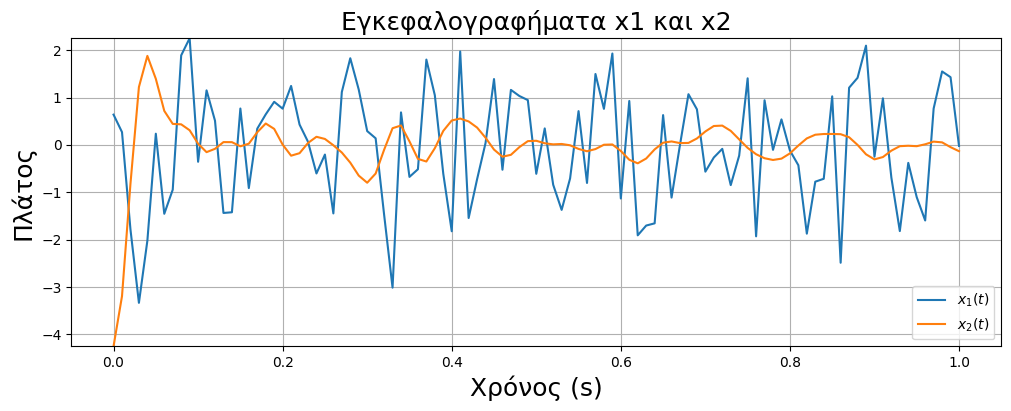

In [93]:
plt.figure(figsize=(12,4))
plt.plot(t, x1, label="$x_1(t)$")
plt.plot(t, x2, label="$x_2(t)$")
plt.ylim([min(np.concatenate((x1,x2))), max(np.concatenate((x1,x2)))])
plt.legend(loc=4)
plt.grid()
plt.xlabel('Χρόνος (s)', fontsize=18)
plt.ylabel('Πλάτος', fontsize=18)
plt.title('Εγκεφαλογραφήματα x1 και x2', fontsize=18)
plt.show()

$\left(\beta'\right)$ Θέλουμε να δούμε το φάσμα πλάτους (το μέτρο του μετασχηματισμού Fourier δηλαδή) των σημάτων αυτών για να αναγνωρίσουμε αν υπάρχει κάποια ισχυρή συνιστώσα στα $10$ Hz - δηλ. ο ρυθμός Άλφα. Χρησιμοποιήστε τον πίνακα ανάλυσης 

$$\large M = e^{-j2\pi f_l t_n}$$

όπως στην 1η Άσκηση αυτής της σειράς για να αναλύσετε τα δυο σήματα στο διάστημα $[3, 20]$ Hz.

In [94]:
ff = np.expand_dims(f, axis=0)                # Επέκταση του διανύσματος συχνότητας όπως έχουμε εξηγήσει στην 1η άσκηση python.
tt = np.expand_dims(t, axis=0)                # Επέκταση του διανύσματος χρόνου, όμοια.

M = np.exp(-1j * 2 * np.pi * ff.T @ tt)       # Πίνακας ανάλυσης Fourier ...
MF1 = dt * np.expand_dims(x1, axis=0) @ M.T   # Μετασχ. Fourier για το σήμα x1 ...
MF2 = dt * np.expand_dims(x2, axis=0) @ M.T   # Μετασχ. Fourier για το σήμα x2 ...

abs1 = np.abs(MF1)                            # Φάσμα πλάτους Χ1(f).
abs2 = np.abs(MF2)                            # Φάσμα πλάτους X2(f).

abs1 = np.squeeze(abs1)                       # Απαλείφουμε την έξτρα διάσταση που βάλαμε πριν για καλύτερο χειρισμό στα γραφήματα.
abs2 = np.squeeze(abs2)                       # --------------------------------------- "" ---------------------------------------

Ας απεικονίσουμε τα δυο φάσματα πλάτους και ας δούμε αν υπάρχει κάποιος ρυθμός Άλφα:

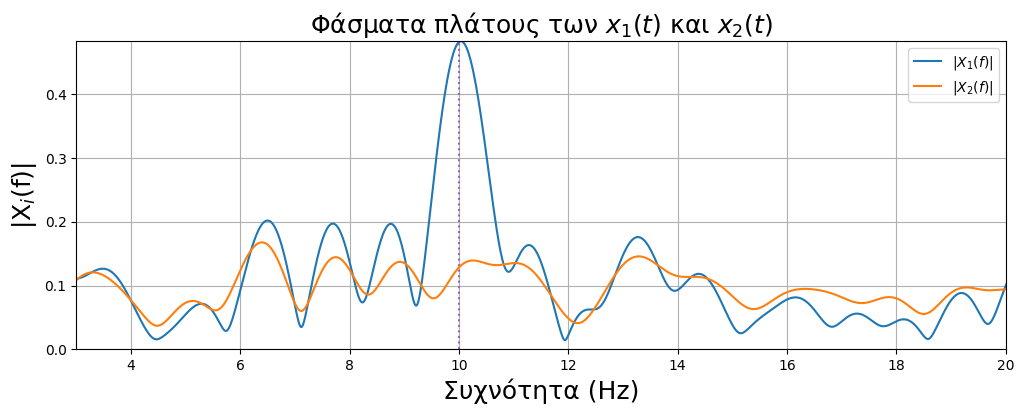

In [95]:
plt.figure(figsize=(12,4))
plt.plot([10, 10], [0, 0.5], linestyle=":", color=f"C{4}")
plt.plot(f, abs1, label="$|X_1(f)|$")
plt.plot(f, abs2, label="$|X_2(f)|$")
plt.plot([10, 11])
plt.xlim([f[0], f[-1]])
plt.ylim([0, max(np.concatenate((abs1, abs2)))])
plt.title("Φάσματα πλάτους των $x_1(t)$ και $x_2(t)$", fontsize=18)
plt.legend()
plt.xlabel('Συχνότητα (Hz)', fontsize=18)
plt.ylabel('|X$_i$(f)|', fontsize=18)
plt.grid()
plt.show()

#### Υπάρχει ρυθμός Άλφα σε κάποιο από τα δυο εγκεφαλογραφήματα? Απαντήστε στο παρακάτω κελί.

- Ναι, υπάρχει ρυθμός άλφα στο πρώτο εγκεφαλογράφημα (χρώμα μπλε), αφού βλέπουμε την κορυφή στα περίπου 10 hz ...

***
***

### Άσκηση 6: Ο μετασχηματισμός Fourier όπως χρησιμοποιείται στη βιομηχανία και την έρευνα

Παρ' όλο που - ελπίζω ότι - καταφέρατε όλες τις παραπάνω εφαρμογές με χρήση αυτού του customized μετασχηματισμού Fourier, θα ήταν πολύ περίεργο να μην υπάρχει κάποιο πιο "άμεσος"/εύκολος τρόπος να υλοποιεί κανείς το μετασχηματισμό Fourier χρησιμοποιώντας απ' ευθείας ένα δειγματοληπτημένο σήμα - χωρίς να χρειάζεται να κάνει ρητά δειγματοληψία στον άξονα του χρόνου και της συχνότητας, να κατασκευάζει πίνακες M, και να υλοποιεί αυτά τα περίεργα αθροίσματα Riemann που είδαμε στις προηγούμενες ασκήσεις.

Ας υποθέσουμε λοιπόν ότι έχουμε το ψηφιακό σήμα αποθηκευμένο στον υπολογιστή μας (είτε είναι ομιλία, είτε μουσική, είτε εγκεφαλογράφημα, καρδιογράφημα, ή οποιαδήποτε άλλη χρονοσειρά). Αυτό σημαίνει ότι έχουμε στα χέρια μας το δειγματοληπτημένο σήμα $x[n] = x(t_n), n = 0, \cdots, N-1$ (που δεν είναι το ίδιο με το ψηφιακό σήμα, που αποτελείται από bits, αλλά ας αφήσουμε στην άκρη αυτή τη λεπτομέρεια). Νωρίτερα προσεγγίσαμε το μετασχ. Fourier με το άθροισμα Riemann, κι επειδή εδώ έχουμε αποθηκευμένες μόλις $N$ τιμές του σήματος συνεχούς χρόνου, το άθροισμα αυτό θα γράφεται ως 

$$X(f) \approx \sum_{n=0}^{N-1}x(t_n)e^{-j2\pi f t_n}\Delta t$$

το οποίο απλοποιείται ως

$$X(f) \approx \Delta t \sum_{n=0}^{N-1}x[n]e^{-j2\pi f t_n}$$

Ξέρουμε ότι οι χρονικές στιγμές $t_n$ έχουν παρθεί ομοιόμορφα στον άξονα του χρόνου ανά $\Delta t$, δηλ.

$$t_n = n\Delta t, \: n \in \Z$$

οπότε

$$X(f) \approx \Delta t\sum_{n=0}^{N-1}x[n]e^{-j2\pi f n\Delta t}$$



Όπως πριν, δειγματοληπτούμε και τον άξονα της συχνότητας, **αλλά αυτή τη φορά**:

1. Επιλέγουμε $N_s$ σημεία του φάσματος, περισσότερα ή όσα ακριβώς είναι το πλήθος των δειγμάτων στο πεδίο του χρόνου ($N_s \geq N$). 
2. Έστω $N_s = N$ για το υπόλοιπο της συζήτησης.
3. Οι συχνότητες που επιλέγουμε απέχουν μεταξύ τους $\Delta f$, δηλ. η δειγματοληψία του φάσματος είναι κι εδώ ομοιόμορφη.

Με άλλα λόγια, οι συχνότητες που επιλέξαμε ισούνται με

$$f_k = \frac{k}{N}\Delta f = \frac{k}{N}\frac{1}{\Delta t}$$

Έτσι, ο μετασχηματισμός γράφεται ως

$$X(f_k) \approx \Delta t \sum_{n=0}^{N-1}x[n]e^{-j2\pi \frac{k}{N}\frac{1}{\Delta t}n\Delta t} = \Delta t \sum_{n=0}^{N-1}x[n]e^{-j2\pi \frac{k}{N}n}$$

δηλ.

$$X(f_k) \approx \Delta t X[k]$$

με $X[k]$ να είναι ένας εύκολα υπολογίσιμος μετασχηματισμός που ονομάζεται **Διακριτός Μετασχηματισμός Fourier**:

$$X[k] = \sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N}, \: k = 0, \cdots, N-1$$

Ο Διακριτός Μετασχηματισμός Fourier είναι επίσης πολύ γρήγορα υπολογίσιμος μέσω του αλγορίθμου του **Γρήγορου Μετασχηματισμού Fourier (Fast Fourier Transform - FFT, https://www.youtube.com/watch?v=nmgFG7PUHfo)**, που σχεδόν όλες οι γλώσσες προγραμματισμού διαθέτουν μέσω εξειδικευμένων πακέτων ανάλυσης δεδομένων. Δηλ.

$$X(f_k) \approx \Delta t \: \textrm{FTT}\{x[n]\} = \Delta t \: X[k]$$

Ως επίδειξη, ας επαναλάβουμε την Άσκηση 1 χρησιμοποιώντας τώρα τη συνάρτηση ``fft`` του υποπακέτου ``fft`` της ``NumPy``:

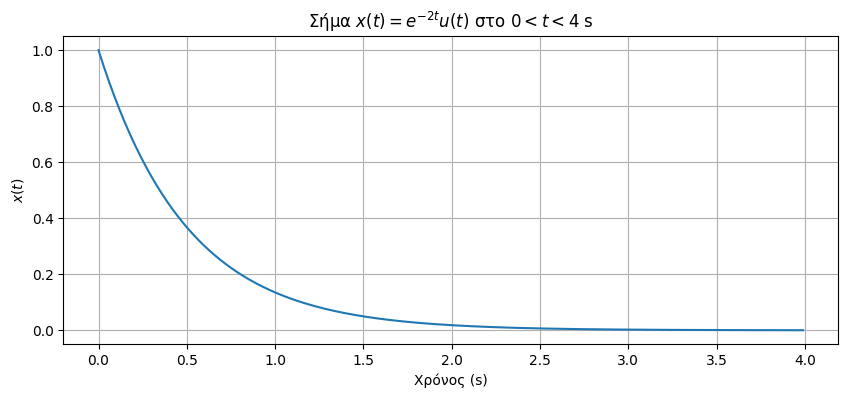

In [96]:
import numpy as np
import matplotlib.pyplot as plt

dt = 1e-2                   # Βήμα στο χρόνο.
t = np.arange(0, 4.0, dt)   # Άξονας χρόνου, από 0 ως 4 δευτερόλεπτα.
x = np.exp(-2*t)            # Σήμα e^{-2t}.
N = len(x)                  # Ν = μήκος σήματος.

plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.xlabel('Χρόνος (s)')
plt.ylabel(r'$x(t)$')
plt.title(r'Σήμα $x(t)=e^{-2t}u(t)$ στο $0 < t < 4$ s')
plt.grid(True)
plt.show()

Ως εδώ, όλα είναι ίδια με πριν. Δεν υπάρχει κάποια αλλαγή στον κώδικα σε σχέση με την 1η Άσκηση (με εξαίρεση ότι κρατήσαμε 4 δευτερόλεπτα του σήματος αντί για 10, που θα έχει μικρή επίπτωση στο αποτέλεσμα).

Πάμε τώρα να κάνουμε την ανάλυση Fourier αποκλειστικά με χρήση έτοιμων συναρτήσεων.

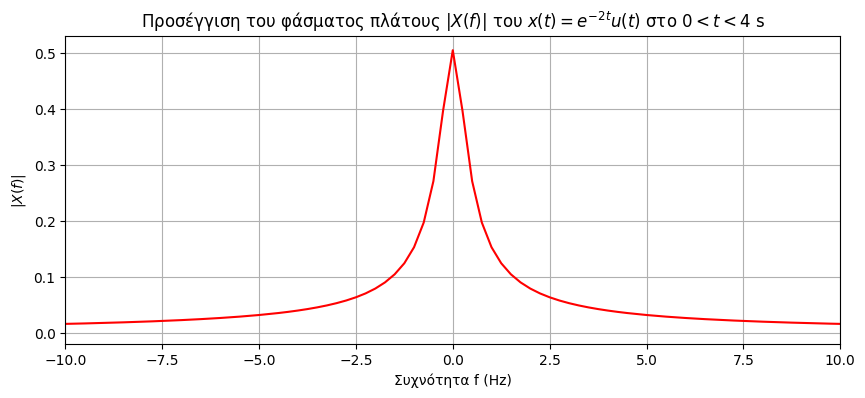

In [97]:
X = dt * np.fft.fft(x, N)     # X(f) ~ Δt X[k]: η προσέγγιση του X(f) μέσω του FFT X[k] από N σημεία.
f = np.fft.fftfreq(N, d=dt)   # Άξονας συχνοτήτων όπως τον ορίσαμε παραπάνω - η συνάρτηση fftfreq τα κάνει όλα για μας!

# Ο μετασχηματισμός που επιστρέφεται χρειάζεται μια μικρή πράξη ώστε να εμφανίζεται σωστά - για λόγους που δεν είναι του παρόντος.
# Η πράξη αυτή εκτελειται από τη συνάρτηση fftshift:
X_shift = np.fft.fftshift(X)
f_shift = np.fft.fftshift(f)

# Τυπώνουμε το φάσμα πλάτους:
plt.figure(figsize=(10, 4))
plt.plot(f_shift, np.abs(X_shift), 'r')
plt.xlabel('Συχνότητα f (Hz)')
plt.xlim([-10, 10]) # Kάνουμε zoom in στο διάστημα [-10, 10] Hz όπως στην 1η Άσκηση...
plt.ylabel(r'$|X(f)|$')
plt.title(r'Προσέγγιση του φάσματος πλάτους $|X(f)|$ του $x(t)=e^{-2t}u(t)$ στο $0 < t < 4$ s')
plt.grid()
plt.show()

Συγκρίνετε το αποτέλεσμα με αυτό της Άσκησης 1. Είναι ουσιαστικά το ίδιο!

---

Πώς θα χρησιμοποιούσαμε τον FFT ως προσέγγιση του μετασχ. Fourier που γνωρίζουμε για να λύσουμε την 5η άσκηση με το ηλεκτροεγκεφαλογράφημα? Ας το δούμε.

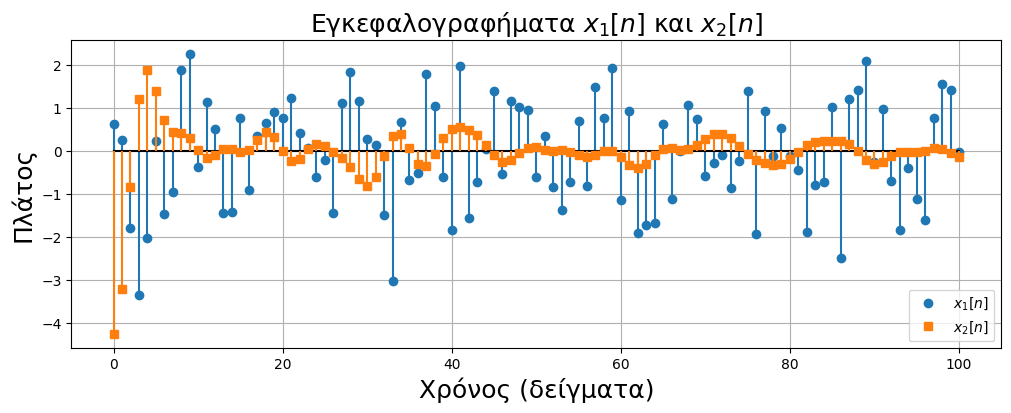

In [98]:
mat = loadmat('EEGn.mat')              # Φορτώνουμε ξανά τα δεδομένα μας.

x1 = np.array(np.squeeze(mat["x1"]))   # Χωρίζουμε τα δυο σήματα όπως πριν.
x2 = np.array(np.squeeze(mat["x2"]))   # --------------- " ---------------
dt = np.array(np.squeeze(mat["dt"]))   # Tο βήμα μας στο χρόνο.

N1 = len(x1)                           # Οι διάρκειες σε δείγματα των σημάτων.
N2 = len(x2)                           # ----------------- " -----------------

n1 = np.arange(0, N1)                  # Ο άξονας του διακριτού (!) χρόνου σε δείγματα.
n2 = np.arange(0, N2)                  # --------------------- " ---------------------

# Ας ξαναδούμε τα ηλεκτροεγκεφαλογραφήματα αλλά αυτή τη φορά στο διακριτό χρόνο (όπως είναι αποθηκευμένα στον υπολογιστή)!
# Δεν είναι απαραίτητο να το κάνετε αυτό, μπορείτε να κρατήσετε τα γραφήματα όπως τα κάνατε στην 5η άσκηση - απλά δείχνουμε μια εναλλακτική απεικόνιση.
fig, ax = plt.subplots(figsize=(12, 4))
m1, s1, b1 = ax.stem(n1, x1, linefmt='C0-', markerfmt='C0o', basefmt='k-')
m2, s2, b2 = ax.stem(n2, x2, linefmt='C1-', markerfmt='C1s', basefmt=' ')
m1.set_label(r'$x_1[n]$')
m2.set_label(r'$x_2[n]$')
ax.legend(loc='lower right')
ax.grid()
ax.set_xlabel('Χρόνος (δείγματα)', fontsize=18)
ax.set_ylabel('Πλάτος', fontsize=18)
ax.set_title('Εγκεφαλογραφήματα $x_1[n]$ και $x_2[n]$', fontsize=18)
plt.show()

Πάμε τώρα να υπολογίσουμε το φάσμα πλάτους καθενός σήματος για να ελέγξουμε την ύπαρξη ρυθμού Άλφα, αλλά αυτή τη φορά χρησιμοποιώντας τον αλγόριθμο FFT!

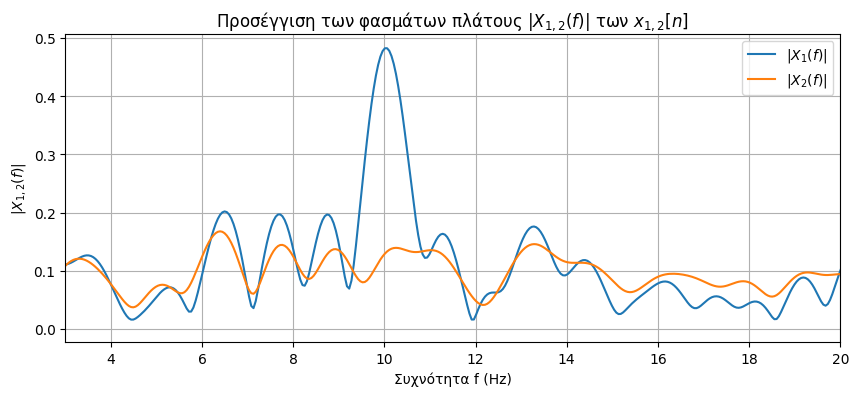

In [99]:
N = 2048 # Σε αντίθεση με το προηγούμενο παράδειγμα, επιλέγουμε να πάρουμε ΠΟΛΛΑ σημεία στο φάσμα του FFT, ήτοι 2048 σημεία αντί για N = διάρκεια σημάτων στο χρόνο (που είναι μόλις 100).

X1 = dt * np.fft.fft(x1, n=N)   # X1(f) ~ Δt X1[k]: η προσέγγιση του X1(f) μέσω του FFT X1[k] ...
f1 = np.fft.fftfreq(N, d=dt)    # Άξονας συχνοτήτων όπως τον ορίσαμε παραπάνω.

X2 = dt * np.fft.fft(x2, n=N)   # X2(f) ~ Δt X2[k]: η προσέγγιση του X2(f) μέσω του FFT X2[k] ...
f2 = np.fft.fftfreq(N, d=dt)    # Άξονας συχνοτήτων όπως τον ορίσαμε παραπάνω.

# Καλούμε την fttshift να μας "φτιάξει" λίγο τα φάσματα όπως πρέπει:
X1_shift = np.fft.fftshift(X1)
f1_shift = np.fft.fftshift(f1)
X2_shift = np.fft.fftshift(X2)
f2_shift = np.fft.fftshift(f2)

plt.figure(figsize=(10, 4))
plt.plot(f1_shift, np.abs(X1_shift), label="$|X_1(f)|$")
plt.plot(f2_shift, np.abs(X2_shift), label="$|X_2(f)|$")
plt.xlim([3, 20])   
plt.xlabel('Συχνότητα f (Hz)')
plt.ylabel(r'$|X_{1,2}(f)|$')
plt.legend()
plt.title(r'Προσέγγιση των φασμάτων πλάτους $|X_{1,2}(f)|$ των $x_{1,2}[n]$')
plt.grid(True)
plt.show()

Αν λοιπόν θέλετε να επεξεργαστείτε με το μετασχηματισμό Fourier σήματα συνεχούς χρόνου που έχετε αποθηκεύσει στον Η/Υ σας, θα χρησιμοποιήσετε τον αλγόριθμο FFT και τον τρόπο που δείχνουμε σε αυτήν την άσκηση, προσαρμόζοντας τη διαδικασία σε μικρότερα παράθυρα όπως στην 3η και 4η Άσκηση. Βλέπετε ότι είναι αρκετά πιο εύκολο και σας δίνει το ίδιο αποτέλεσμα με την αναλυτική μέθοδο που εισάγαμε στην 1η Άσκηση.

Φυσικά, στην εξήγησή μας σχετικά με τον FFT υπάρχουν κάποια κενά στη θεωρία, που θα "κλείσουν" αν προτιμήσετε του χρόνου (ή αργότερα) να παρακολουθήσετε το μάθημα ΗΥ370-Ψηφιακή Επεξεργασία Σημάτων. 😁


## Παραδοτέα:
*** 
### Μετονομάστε το **συμπληρωμένο και με εκτελεσμένο κάθε κελί κώδικα** notebook σε 

## *HY215-Lab4-2026-CSDXXXX.ipynb*, 

### με *XXXX* ο αριθμός μητρώου σας. 

### Αν είστε με προσωρινό κωδικό λόγω μεταγραφής, τότε ονομάστε το αρχείο σας 

## *HY215-Lab4-2026-mtgXXXX.ipynb*, 

### με *XXXX* ο προσωρινός αριθμός μητρώου σας.

### Αν είστε από άλλο τμήμα εκτός του CSD, τότε ονομάστε το αρχείο σας ως

## *HY215-Lab4-2026-DPTXXXX.ipynb*, 

### με DTP ένα εκ των {MATH, PHYS} και *XXXX* ο αριθμός μητρώου σας. 

### Στείλτε το μετονομασμένο notebook ως επισυναπτόμενο αρχείο με e-mail στο patsoura@csd.uoc.gr . 

### Στο e-mail θα αναγράφετε:

### - Τίτλος: [ΗΥ215] 4ο εργαστήριο Python

### και στο σώμα του e-mail τα παρακάτω: 

### - Ονοματεπώνυμο
### - ΑΜ

#### **Σημείωση**: μπορείτε να κάνετε επαναπαραδόσεις του εργαστηρίου - αν χρειαστεί. Χρησιμοποιήστε τίτλο

#### [ΗΥ215] Επαναπαράδοση 4ου εργαστηρίου Python

#### και κρατήστε τα ίδια στοιχεία στο σώμα του e-mail.

### ΠΡΟΣΕΞΤΕ: Το παραδοτέο αρχείο σας πρέπει να έχει extension .ipynb, και ΟΧΙ κάτι άλλο!!